In [1]:
print("LEAD Energy Anomaly Detection Project")
print("Python is working!")

LEAD Energy Anomaly Detection Project
Python is working!


In [2]:
import pandas as pd

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training data shape:", train_df.shape)
display(train_df.head())

print("Test data shape:", test_df.shape)
display(test_df.head())

Training data shape: (1749494, 4)


,building_id,timestamp,meter_reading,anomaly
0,1,2016-01-01 00:00:00,NaN,0
1,32,2016-01-01 00:00:00,NaN,0
2,41,2016-01-01 00:00:00,NaN,0
3,55,2016-01-01 00:00:00,NaN,0
4,69,2016-01-01 00:00:00,NaN,0


Test data shape: (1800567, 4)


,row_id,building_id,timestamp,meter_reading
0,0,18,2016-01-01 00:00:00,NaN
1,1,19,2016-01-01 00:00:00,NaN
2,2,26,2016-01-01 00:00:00,NaN
3,3,38,2016-01-01 00:00:00,NaN
4,4,39,2016-01-01 00:00:00,NaN


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

# Dataset files are in the current project folder
data_dir = Path(".")

train_df = pd.read_csv(data_dir / "train.csv")
test_df = pd.read_csv(data_dir / "test.csv")

print("Training data loaded successfully!")
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training data loaded successfully!
Training shape: (1749494, 4)
Testing shape: (1800567, 4)


In [4]:
# Inspect all dataset files
files = [
    "train.csv",
    "test.csv",
    "train_features.csv",
    "test_features.csv",
    "sample_submission.csv"
]

for filename in files:
    path = data_dir / filename

    if path.exists():
        # Read only the header first to avoid loading large files
        columns = pd.read_csv(path, nrows=0).columns.tolist()

        print(f"\nFile: {filename}")
        print("Columns:", columns)

        # Count rows efficiently in chunks
        row_count = sum(
            len(chunk)
            for chunk in pd.read_csv(path, chunksize=200_000)
        )

        print("Rows:", row_count)
        print("Columns count:", len(columns))
    else:
        print(f"\nFile not found: {filename}")


File: train.csv
Columns: ['building_id', 'timestamp', 'meter_reading', 'anomaly']
Rows: 1749494
Columns count: 4

File: test.csv
Columns: ['row_id', 'building_id', 'timestamp', 'meter_reading']
Rows: 1800567
Columns count: 4

File: train_features.csv
Columns: ['building_id', 'timestamp', 'meter_reading', 'anomaly', 'site_id', 'primary_use', 'square_feet', 'year_built', 'floor_count', 'air_temperature', 'cloud_coverage', 'dew_temperature', 'precip_depth_1_hr', 'sea_level_pressure', 'wind_direction', 'wind_speed', 'air_temperature_mean_lag7', 'air_temperature_max_lag7', 'air_temperature_min_lag7', 'air_temperature_std_lag7', 'air_temperature_mean_lag73', 'air_temperature_max_lag73', 'air_temperature_min_lag73', 'air_temperature_std_lag73', 'hour', 'weekday', 'month', 'year', 'weekday_hour', 'hour_x', 'hour_y', 'month_x', 'month_y', 'weekday_x', 'weekday_y', 'building_weekday_hour', 'building_weekday', 'building_month', 'building_hour', 'building_meter', 'is_holiday', 'gte_hour', 'gte_we

In [5]:
# Display the first five rows
print("First five rows of training data:")
display(train_df.head())

print("First five rows of testing data:")
display(test_df.head())

First five rows of training data:


,building_id,timestamp,meter_reading,anomaly
0,1,2016-01-01 00:00:00,NaN,0
1,32,2016-01-01 00:00:00,NaN,0
2,41,2016-01-01 00:00:00,NaN,0
3,55,2016-01-01 00:00:00,NaN,0
4,69,2016-01-01 00:00:00,NaN,0


First five rows of testing data:


,row_id,building_id,timestamp,meter_reading
0,0,18,2016-01-01 00:00:00,NaN
1,1,19,2016-01-01 00:00:00,NaN
2,2,26,2016-01-01 00:00:00,NaN
3,3,38,2016-01-01 00:00:00,NaN
4,4,39,2016-01-01 00:00:00,NaN


In [6]:
#Check column names, data types and memory usage
print("TRAINING DATA INFORMATION")
train_df.info()

print("\nTESTING DATA INFORMATION")
test_df.info()

print("\nTraining data types:")
display(train_df.dtypes.to_frame(name="Data Type"))

print("\nTraining memory usage:")
print(f"{train_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

TRAINING DATA INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1749494 entries, 0 to 1749493
Data columns (total 4 columns):
 #   Column         Dtype  
---  ------         -----  
 0   building_id    int64  
 1   timestamp      str    
 2   meter_reading  float64
 3   anomaly        int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 53.4 MB

TESTING DATA INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1800567 entries, 0 to 1800566
Data columns (total 4 columns):
 #   Column         Dtype  
---  ------         -----  
 0   row_id         int64  
 1   building_id    int64  
 2   timestamp      str    
 3   meter_reading  float64
dtypes: float64(1), int64(2), str(1)
memory usage: 54.9 MB

Training data types:


,Data Type
building_id,int64
timestamp,str
meter_reading,float64
anomaly,int64



Training memory usage:
153.50 MB


In [7]:
# Step 3: Check missing values

print("Missing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in testing data:")
print(test_df.isnull().sum())

# Calculate missing-value percentages
missing_percentage = (
    train_df.isnull().mean() * 100
).round(2)

print("\nMissing-value percentage in training data:")
print(missing_percentage)


Missing values in training data:
building_id           0
timestamp             0
meter_reading    107653
anomaly               0
dtype: int64

Missing values in testing data:
row_id               0
building_id          0
timestamp            0
meter_reading    94864
dtype: int64

Missing-value percentage in training data:
building_id      0.00
timestamp        0.00
meter_reading    6.15
anomaly          0.00
dtype: float64


In [8]:
# Step 4: Check duplicate records

print("Duplicate rows in training data:")
print(train_df.duplicated().sum())

print("\nDuplicate rows in testing data:")
print(test_df.duplicated().sum())

# Check duplicate IDs, if the ID column exists
if "id" in train_df.columns:
    print("\nDuplicate IDs in training data:")
    print(train_df["id"].duplicated().sum())

if "id" in test_df.columns:
    print("\nDuplicate IDs in testing data:")
    print(test_df["id"].duplicated().sum())

Duplicate rows in training data:
0

Duplicate rows in testing data:
0


## Step 5: Focused Training Data Quality Audit

This section checks missing values, anomaly-label balance, duplicate records, and timestamp coverage in the training data. It scans `train_features.csv` in chunks to avoid loading the full feature file into memory. The audit does not remove rows, change labels, or overwrite the original timestamp column.

In [9]:
from pathlib import Path
import pandas as pd

# Reuse the DataFrame from earlier notebook cells; load it only if needed.
data_dir = Path(globals().get("data_dir", Path(".")))
if "train_df" not in globals():
    train_path = data_dir / "train.csv"
    if not train_path.exists():
        raise FileNotFoundError(f"Training file not found: {train_path.resolve()}")
    train_df = pd.read_csv(train_path)

required_columns = ["meter_reading", "anomaly", "building_id", "timestamp"]
missing_columns = [column for column in required_columns if column not in train_df.columns]
if missing_columns:
    raise KeyError(f"Training data is missing required audit columns: {missing_columns}")

row_count = len(train_df)
print(f"Raw training data: {row_count:,} rows")

# Missing-value counts and percentages for the raw training columns.
raw_missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percent": (train_df.isna().mean() * 100).round(2),
})
print("\nMissing values in raw training data:")
display(raw_missing)

# Include missing labels in the distribution; labels are only being audited.
label_counts = train_df["anomaly"].value_counts(dropna=False)
label_distribution = pd.DataFrame({
    "count": label_counts,
    "percent": (label_counts / row_count * 100).round(3),
})
print("\nAnomaly-label distribution (including missing labels):")
display(label_distribution)

# Count exact duplicate rows and repeated valid building-timestamp keys.
full_duplicate_rows = int(train_df.duplicated().sum())
key_columns = ["building_id", "timestamp"]
valid_key_mask = train_df[key_columns].notna().all(axis=1)
valid_keys = train_df.loc[valid_key_mask, key_columns]
duplicate_key_mask = valid_keys.duplicated(keep=False)
duplicate_key_count = int(valid_keys.loc[duplicate_key_mask].drop_duplicates().shape[0])
duplicate_key_rows = int(duplicate_key_mask.sum())
extra_duplicate_key_rows = int(valid_keys.duplicated().sum())
print("\nDuplicate-record checks:")
print(f"Fully duplicated rows (excluding each first occurrence): {full_duplicate_rows:,}")
print(f"Distinct duplicated (building_id, timestamp) keys: {duplicate_key_count:,}")
print(f"Rows belonging to duplicated valid keys: {duplicate_key_rows:,}")
print(f"Extra rows beyond the first record for each duplicated key: {extra_duplicate_key_rows:,}")
print("Repeated records are reported only; investigate them before deciding whether any should be removed.")

# Parse into a separate Series so the original timestamp column is unchanged.
parsed_timestamps = pd.to_datetime(train_df["timestamp"], errors="coerce")
timestamp_missing = int(train_df["timestamp"].isna().sum())
timestamp_invalid = int((train_df["timestamp"].notna() & parsed_timestamps.isna()).sum())
valid_timestamps = parsed_timestamps.dropna()
unique_buildings = int(train_df["building_id"].nunique(dropna=True))
print("\nTimestamp coverage:")
print(f"Missing timestamps: {timestamp_missing:,}")
print(f"Non-missing timestamps that could not be parsed: {timestamp_invalid:,}")
print(f"Earliest valid timestamp: {valid_timestamps.min() if not valid_timestamps.empty else 'None'}")
print(f"Latest valid timestamp: {valid_timestamps.max() if not valid_timestamps.empty else 'None'}")
print(f"Unique non-missing buildings: {unique_buildings:,}")

# Summarize each building's observed range without printing a huge table.
timestamp_by_building = pd.DataFrame({
    "building_id": train_df["building_id"],
    "parsed_timestamp": parsed_timestamps,
})
building_coverage = timestamp_by_building.groupby("building_id", dropna=True).agg(
    first_valid_timestamp=("parsed_timestamp", "min"),
    last_valid_timestamp=("parsed_timestamp", "max"),
    unique_valid_timestamps=("parsed_timestamp", "nunique"),
    row_count=("parsed_timestamp", "size"),
)
print(f"Buildings summarized (non-missing building_id): {len(building_coverage):,}")
if not building_coverage.empty:
    print("Per-building unique timestamp coverage (summary):")
    display(building_coverage["unique_valid_timestamps"].describe().to_frame().round(2))
    print("Ten buildings with the most unique valid timestamps:")
    display(building_coverage.sort_values("unique_valid_timestamps", ascending=False).head(10))

# Scan the wide feature file in chunks; retain only per-column missing counts.
feature_path = data_dir / "train_features.csv"
if not feature_path.exists():
    raise FileNotFoundError(f"Training feature file not found: {feature_path.resolve()}")
feature_missing_counts = None
feature_row_count = 0
for chunk in pd.read_csv(feature_path, chunksize=50_000):
    chunk_missing = chunk.isna().sum()
    feature_missing_counts = chunk_missing if feature_missing_counts is None else feature_missing_counts.add(chunk_missing, fill_value=0)
    feature_row_count += len(chunk)

feature_missing_counts = feature_missing_counts.astype("int64")
feature_missing_summary = pd.DataFrame({
    "missing_count": feature_missing_counts,
    "missing_percent": (feature_missing_counts / feature_row_count * 100).round(2),
})
feature_columns_with_missing = feature_missing_summary[feature_missing_summary["missing_count"] > 0]
print("\nTraining feature-file missing-value summary (read in 50,000-row chunks):")
print(f"Rows scanned: {feature_row_count:,}; columns scanned: {len(feature_missing_summary):,}")
print(f"Columns with at least one missing value: {len(feature_columns_with_missing):,} of {len(feature_missing_summary):,}")
print(f"Total missing cells: {int(feature_missing_counts.sum()):,}")
if feature_columns_with_missing.empty:
    print("No missing values were found in the scanned feature file.")
else:
    print("Columns with missing values:")
    display(feature_columns_with_missing.sort_values("missing_count", ascending=False))

print("\nHow to use these results:")
print("- Missing readings and features may need a documented handling strategy before modeling.")
print("- Label imbalance affects evaluation: later comparisons should emphasize precision-recall metrics, not accuracy alone.")
print("- Repeated building-time keys and invalid timestamps need investigation; this audit does not remove or repair them.")
print("- Confirm feature provenance and keep anomaly labels out of model inputs in later steps.")

Raw training data: 1,749,494 rows

Missing values in raw training data:


,missing_count,missing_percent
building_id,0,0.00
timestamp,0,0.00
meter_reading,107653,6.15
anomaly,0,0.00



Anomaly-label distribution (including missing labels):


,count,percent
anomaly,,
0,1712198,97.868
1,37296,2.132



Duplicate-record checks:
Fully duplicated rows (excluding each first occurrence): 0
Distinct duplicated (building_id, timestamp) keys: 0
Rows belonging to duplicated valid keys: 0
Extra rows beyond the first record for each duplicated key: 0
Repeated records are reported only; investigate them before deciding whether any should be removed.

Timestamp coverage:
Missing timestamps: 0
Non-missing timestamps that could not be parsed: 0
Earliest valid timestamp: 2016-01-01 00:00:00
Latest valid timestamp: 2016-12-31 23:00:00
Unique non-missing buildings: 200
Buildings summarized (non-missing building_id): 200
Per-building unique timestamp coverage (summary):


...

Ten buildings with the most unique valid timestamps:


,first_valid_timestamp,last_valid_timestamp,unique_valid_timestamps,row_count
building_id,,,,
1,2016-01-01,2016-12-31 23:00:00,8784,8784
32,2016-01-01,2016-12-31 23:00:00,8784,8784
41,2016-01-01,2016-12-31 23:00:00,8784,8784
55,2016-01-01,2016-12-31 23:00:00,8784,8784
69,2016-01-01,2016-12-31 23:00:00,8784,8784
79,2016-01-01,2016-12-31 23:00:00,8784,8784
82,2016-01-01,2016-12-31 23:00:00,8784,8784
91,2016-01-01,2016-12-31 23:00:00,8784,8784
107,2016-01-01,2016-12-31 23:00:00,8784,8784



Training feature-file missing-value summary (read in 50,000-row chunks):
Rows scanned: 1,749,494; columns scanned: 57
Columns with at least one missing value: 1 of 57
Total missing cells: 107,653
Columns with missing values:


,missing_count,missing_percent
meter_reading,107653,6.15



How to use these results:
- Missing readings and features may need a documented handling strategy before modeling.
- Label imbalance affects evaluation: later comparisons should emphasize precision-recall metrics, not accuracy alone.
- Repeated building-time keys and invalid timestamps need investigation; this audit does not remove or repair them.
- Confirm feature provenance and keep anomaly labels out of model inputs in later steps.


## Step 2: Leakage-Aware Data Review and Preparation

This step verifies how the raw and precomputed files align, examines missing readings, records feature-provenance limitations, and creates chronological development, validation, and final-holdout partitions. It does not train models, tune parameters, impute readings, remove rows, or use anomaly labels as predictors.

The project folder currently contains no README, feature-generation script, or label documentation. Therefore, the meaning of `anomaly` beyond its observed values and the provenance of precomputed fields cannot be established from this workspace. Treat the label as evaluation-only and treat precomputed features as unverified until their generating code or reliable documentation is available.

**Missing-reading policy for this stage:** retain every original row and do not impute. For later reading-based model comparisons, use the same rows with observed readings in each validation/holdout period and report coverage. This avoids inventing readings, but complete-observation evaluation cannot detect missingness itself and may be biased if missingness is systematic. Consider a separate operational missing-data alert only after its cause is investigated.

**Building coverage:** retain buildings with partial coverage rather than requiring a complete-year panel. The observed coverage differs by building; some validation and final-holdout buildings have no non-missing readings. Report those coverage gaps, and do not interpret them as normal model outcomes.

In [10]:
from pathlib import Path
import pandas as pd

# Reuse previously loaded raw frames when available; otherwise load only raw files.
project_dir = Path(globals().get("data_dir", Path.cwd()))
train_path = project_dir / "train.csv"
test_path = project_dir / "test.csv"
train_features_path = project_dir / "train_features.csv"
test_features_path = project_dir / "test_features.csv"
submission_path = project_dir / "sample_submission.csv"

if "train_df" not in globals():
    train_df = pd.read_csv(train_path)
if "test_df" not in globals():
    test_df = pd.read_csv(test_path)

file_paths = {
    "train.csv": train_path,
    "test.csv": test_path,
    "train_features.csv": train_features_path,
    "test_features.csv": test_features_path,
}
for file_name, file_path in file_paths.items():
    if not file_path.exists():
        raise FileNotFoundError(f"Required project file was not found: {file_path.resolve()}")
    print(f"{file_name}: {file_path.stat().st_size / (1024 ** 2):.1f} MiB")

# Headers are read separately; sample rows are used only to report observed dtypes.
train_feature_columns = pd.read_csv(train_features_path, nrows=0).columns.tolist()
test_feature_columns = pd.read_csv(test_features_path, nrows=0).columns.tolist()
print("\nRaw and feature schema:")
print(f"train.csv: {len(train_df.columns)} columns; {len(train_df):,} rows")
print(f"train_features.csv: {len(train_feature_columns)} columns")
print(f"test.csv: {len(test_df.columns)} columns; {len(test_df):,} rows")
print(f"test_features.csv: {len(test_feature_columns)} columns")
print("Raw training dtypes:")
display(train_df.dtypes.astype(str).to_frame("dtype"))
print("Raw test dtypes:")
display(test_df.dtypes.astype(str).to_frame("dtype"))
if submission_path.exists():
    submission_columns = pd.read_csv(submission_path, nrows=0).columns.tolist()
    submission_rows = sum(
        len(chunk) for chunk in pd.read_csv(submission_path, chunksize=200_000)
    )
    print(
        f"sample_submission.csv: {submission_rows:,} rows; "
        f"columns={submission_columns}; schema only, not model output"
    )
print("Train-only feature columns:", sorted(set(train_feature_columns) - set(test_feature_columns)))
print("Test-only feature columns:", sorted(set(test_feature_columns) - set(train_feature_columns)))
print("Shared feature columns:", len(set(train_feature_columns) & set(test_feature_columns)))
print("Missing values in raw test data:")
display(pd.DataFrame({
    "missing_count": test_df.isna().sum(),
    "missing_percent": (test_df.isna().mean() * 100).round(2),
}))
print("Sampled training feature dtypes:")
display(pd.read_csv(train_features_path, nrows=1_000).dtypes.astype(str).to_frame("dtype"))
print("Sampled test feature dtypes:")
display(pd.read_csv(test_features_path, nrows=1_000).dtypes.astype(str).to_frame("dtype"))

def compare_raw_to_feature_rows(raw_frame, feature_path, shared_columns, chunk_size=50_000):
    """Compare shared source values by row position without loading features at once."""
    mismatch_counts = {column: 0 for column in shared_columns}
    feature_row_count = 0
    for feature_chunk in pd.read_csv(
        feature_path, usecols=shared_columns, chunksize=chunk_size
    ):
        end = feature_row_count + len(feature_chunk)
        raw_chunk = raw_frame.iloc[feature_row_count:end][shared_columns].reset_index(drop=True)
        feature_chunk = feature_chunk.reset_index(drop=True)
        if len(raw_chunk) != len(feature_chunk):
            raise ValueError(f"Row-count mismatch while checking {feature_path.name}.")
        for column in shared_columns:
            left = raw_chunk[column]
            right = feature_chunk[column]
            equal = left.eq(right) | (left.isna() & right.isna())
            mismatch_counts[column] += int((~equal).sum())
        feature_row_count = end
    if feature_row_count != len(raw_frame):
        raise ValueError(
            f"Row-count mismatch for {feature_path.name}: "
            f"raw={len(raw_frame):,}, features={feature_row_count:,}."
        )
    return feature_row_count, mismatch_counts

train_shared = [column for column in train_df.columns if column in train_feature_columns]
test_shared = [column for column in test_df.columns if column in test_feature_columns]
train_aligned_rows, train_mismatches = compare_raw_to_feature_rows(
    train_df, train_features_path, train_shared
)
test_aligned_rows, test_mismatches = compare_raw_to_feature_rows(
    test_df, test_features_path, test_shared
)
print("\nChunked raw-to-feature row-order and source-value comparison:")
print(f"Training aligned rows: {train_aligned_rows:,}; mismatches by column: {train_mismatches}")
print(f"Test aligned rows: {test_aligned_rows:,}; mismatches by column: {test_mismatches}")
print("Zero mismatches means matching source values in the same row positions; no join was performed.")

# Missing readings by month and building; do not delete or fill these records.
audit_timestamps = pd.to_datetime(train_df["timestamp"], errors="coerce")
missing_reading = train_df["meter_reading"].isna()
missing_by_month = pd.DataFrame({
    "month": audit_timestamps.dt.to_period("M"),
    "missing_reading": missing_reading,
}).groupby("month").agg(
    rows=("missing_reading", "size"),
    missing=("missing_reading", "sum"),
)
missing_by_month["missing_percent"] = (
    missing_by_month["missing"] / missing_by_month["rows"] * 100
).round(2)
print("\nMissing meter readings by month:")
display(missing_by_month)

missing_by_building = pd.DataFrame({
    "building_id": train_df["building_id"],
    "missing_reading": missing_reading,
}).groupby("building_id").agg(
    rows=("missing_reading", "size"),
    missing=("missing_reading", "sum"),
)
missing_by_building["missing_percent"] = (
    missing_by_building["missing"] / missing_by_building["rows"] * 100
).round(2)
print(
    f"Buildings with missing readings: {(missing_by_building['missing'] > 0).sum()} "
    f"of {len(missing_by_building)}"
)
print("Per-building missing-reading percentage summary:")
display(missing_by_building["missing_percent"].describe().round(2).to_frame())
print("Buildings with the most missing readings:")
display(missing_by_building.sort_values("missing", ascending=False).head(10))
missing_by_label = pd.DataFrame({
    "anomaly": train_df["anomaly"],
    "reading_missing": missing_reading,
}).groupby("anomaly", dropna=False).agg(
    rows=("reading_missing", "size"),
    missing_readings=("reading_missing", "sum"),
)
missing_by_label["missing_percent"] = (
    missing_by_label["missing_readings"] / missing_by_label["rows"] * 100
).round(3)
print("Missing readings by provided anomaly-label value (audit only):")
display(missing_by_label)

print("\nLabel documentation check:")
print("The workspace has no project README, label definition, or feature-generation source code.")
print("Observed anomaly values:", train_df["anomaly"].value_counts(dropna=False).sort_index().to_dict())
print("Treat anomaly as evaluation-only; its ground-truth definition is not documented locally.")

train.csv: 55.0 MiB
test.csv: 65.9 MiB
train_features.csv: 555.1 MiB
test_features.csv: 580.0 MiB

Raw and feature schema:
train.csv: 4 columns; 1,749,494 rows
train_features.csv: 57 columns
test.csv: 4 columns; 1,800,567 rows
test_features.csv: 57 columns
Raw training dtypes:


,dtype
building_id,int64
timestamp,str
meter_reading,float64
anomaly,int64


Raw test dtypes:


,dtype
row_id,int64
building_id,int64
timestamp,str
meter_reading,float64


sample_submission.csv: 1,800,567 rows; columns=['row_id', 'anomaly']; schema only, not model output
Train-only feature columns: ['anomaly']
Test-only feature columns: ['row_id']
Shared feature columns: 56
Missing values in raw test data:


...

Buildings with the most missing readings:


,rows,missing,missing_percent
building_id,,,
144,8784,5410,61.59
112,8784,5350,60.91
107,8784,3808,43.35
69,8784,3651,41.56
886,8780,3541,40.33
693,8784,3479,39.61
1,8784,3466,39.46
41,8784,3430,39.05
91,8784,3387,38.56


Missing readings by provided anomaly-label value (audit only):


,rows,missing_readings,missing_percent
anomaly,,,
0,1712198,107653,6.287
1,37296,0,0.000



Label documentation check:
The workspace has no project README, label definition, or feature-generation source code.
Observed anomaly values: {0: 1712198, 1: 37296}
Treat anomaly as evaluation-only; its ground-truth definition is not documented locally.


In [11]:
# Categorize by evidence available in the workspace, not by column name alone.
feature_groups = {
    "Direct observation (candidate only)": ["meter_reading"],
    "Entity/time keys (metadata, not predictors)": ["building_id", "timestamp", "row_id"],
    "Unsafe target/identifier fields": ["anomaly", "row_id"],
    "Uncertain building/site metadata": [
        "site_id", "primary_use", "square_feet", "year_built", "floor_count"
    ],
    "Uncertain weather observations": [
        "air_temperature", "cloud_coverage", "dew_temperature", "precip_depth_1_hr",
        "sea_level_pressure", "wind_direction", "wind_speed"
    ],
    "Uncertain lagged weather summaries": [
        "air_temperature_mean_lag7", "air_temperature_max_lag7",
        "air_temperature_min_lag7", "air_temperature_std_lag7",
        "air_temperature_mean_lag73", "air_temperature_max_lag73",
        "air_temperature_min_lag73", "air_temperature_std_lag73"
    ],
    "Recompute from timestamp; stored provenance unverified": [
        "hour", "weekday", "month", "year", "weekday_hour", "hour_x", "hour_y",
        "month_x", "month_y", "weekday_x", "weekday_y", "is_holiday"
    ],
    "Uncertain building/time aggregates or string combinations": [
        "building_weekday_hour", "building_weekday", "building_month",
        "building_hour", "building_meter"
    ],
    "Uncertain gte encodings; exclude pending provenance": [
        column for column in train_feature_columns if column.startswith("gte_")
    ],
}

risk_rows = []
for status, columns in feature_groups.items():
    present = [column for column in columns if column in train_feature_columns or column in train_df.columns]
    if present:
        risk_rows.append({"evidence_status": status, "columns": ", ".join(present)})
feature_risk_register = pd.DataFrame(risk_rows)
print("\nFeature provenance register:")
display(feature_risk_register)
print(
    "No generator code or documentation was found to establish whether lag, aggregate, "
    "weather, or gte fields use only past/current information or avoid label-derived statistics."
)
print(
    "The gte_ names may suggest an encoding, but their meaning is not verified. "
    "Do not use these fields until provenance confirms the fit data, time window, and target."
)
print(
    "Calendar values can be recreated from parsed timestamps for known time fields; "
    "do not rely on precomputed versions until checked against a documented definition."
)
print("Anomaly is never a predictor; row_id is an identifier and never a predictor.")


Feature provenance register:


,evidence_status,columns
0,Direct observation (candidate only),meter_reading
1,"Entity/time keys (metadata, not predictors)","building_id, timestamp"
2,Unsafe target/identifier fields,anomaly
3,Uncertain building/site metadata,"site_id, primary_use, square_feet, year_built,..."
4,Uncertain weather observations,"air_temperature, cloud_coverage, dew_temperatu..."
5,Uncertain lagged weather summaries,"air_temperature_mean_lag7, air_temperature_max..."
6,Recompute from timestamp; stored provenance un...,"hour, weekday, month, year, weekday_hour, hour..."
7,Uncertain building/time aggregates or string c...,"building_weekday_hour, building_weekday, build..."
8,Uncertain gte encodings; exclude pending prove...,"gte_hour, gte_weekday, gte_month, gte_building..."


No generator code or documentation was found to establish whether lag, aggregate, weather, or gte fields use only past/current information or avoid label-derived statistics.
The gte_ names may suggest an encoding, but their meaning is not verified. Do not use these fields until provenance confirms the fit data, time window, and target.
Calendar values can be recreated from parsed timestamps for known time fields; do not rely on precomputed versions until checked against a documented definition.
Anomaly is never a predictor; row_id is an identifier and never a predictor.


In [12]:
# Prepare chronological partitions only. No imputation, encoding, or model fitting occurs here.
if train_df["timestamp"].isna().any():
    raise ValueError("Missing timestamps must be resolved before chronological partitioning.")

prepared_train = train_df.copy()
prepared_train["timestamp_parsed"] = pd.to_datetime(
    prepared_train["timestamp"], errors="coerce"
)
if prepared_train["timestamp_parsed"].isna().any():
    raise ValueError("Some non-missing timestamps could not be parsed.")

# Preserve source row identity for traceability while sorting by time.
prepared_train["source_row_index"] = prepared_train.index
prepared_train = prepared_train.sort_values(
    ["timestamp_parsed", "building_id"], kind="stable"
).reset_index(drop=True)

development_end = pd.Timestamp("2016-09-01 00:00:00")
validation_end = pd.Timestamp("2016-11-01 00:00:00")
final_holdout_end = pd.Timestamp("2017-01-01 00:00:00")
split_masks = {
    "development_training": prepared_train["timestamp_parsed"] < development_end,
    "validation": (
        (prepared_train["timestamp_parsed"] >= development_end)
        & (prepared_train["timestamp_parsed"] < validation_end)
    ),
    "final_holdout": (
        (prepared_train["timestamp_parsed"] >= validation_end)
        & (prepared_train["timestamp_parsed"] < final_holdout_end)
    ),
}
if sum(int(mask.sum()) for mask in split_masks.values()) != len(prepared_train):
    raise ValueError("The proposed date ranges do not cover every training row exactly once.")

# Keep the unsupervised input separate from the label and grouping/time metadata.
predictor_columns = ["meter_reading"]
excluded_from_predictors = [
    "anomaly", "row_id", "timestamp", "timestamp_parsed", "building_id",
    "source_row_index", "all unverified precomputed train_features.csv fields",
]
X_prepared = prepared_train[predictor_columns].copy()
evaluation_labels = prepared_train["anomaly"].copy()
row_metadata = prepared_train[["building_id", "timestamp_parsed", "source_row_index"]].copy()
observed_reading_masks = {
    name: mask & X_prepared["meter_reading"].notna()
    for name, mask in split_masks.items()
}

print("\nChronological split protocol (based on verified Jan-Dec 2016 coverage):")
print("Development/training: 2016-01-01 through 2016-08-31 (before 2016-09-01)")
print("Validation: 2016-09-01 through 2016-10-31 (before 2016-11-01)")
print("Final holdout: 2016-11-01 through 2016-12-31 (before 2017-01-01)")
print("Final holdout is reserved: do not use it for feature selection, tuning, or threshold selection.")
print("\nRows, observed readings, and buildings in each partition:")
for name, mask in split_masks.items():
    partition = prepared_train.loc[mask]
    reading_mask = observed_reading_masks[name]
    per_building_readings = partition.groupby("building_id")["meter_reading"].count()
    print(
        f"{name}: rows={len(partition):,}; observed_readings={int(reading_mask.sum()):,}; "
        f"missing_readings={int(partition['meter_reading'].isna().sum()):,}; "
        f"buildings={partition['building_id'].nunique():,}; "
        f"buildings_with_zero_readings={int((per_building_readings == 0).sum()):,}"
    )

print("\nPrepared predictor columns:", predictor_columns)
print("Evaluation-only label column: anomaly (kept separately as evaluation_labels)")
print("Grouping/time metadata columns:", list(row_metadata.columns))
print("Excluded from predictors:", excluded_from_predictors)
print("Missing readings remain missing. The observation masks identify available readings; no rows were removed.")
print(
    "Later model comparisons must use the same validation observation mask and the same reserved "
    "final-holdout observation mask. The labels must not inform unsupervised fitting."
)


Chronological split protocol (based on verified Jan-Dec 2016 coverage):
Development/training: 2016-01-01 through 2016-08-31 (before 2016-09-01)
Validation: 2016-09-01 through 2016-10-31 (before 2016-11-01)
Final holdout: 2016-11-01 through 2016-12-31 (before 2017-01-01)
Final holdout is reserved: do not use it for feature selection, tuning, or threshold selection.

Rows, observed readings, and buildings in each partition:
development_training: rows=1,166,122; observed_readings=1,083,509; missing_readings=82,613; buildings=200; buildings_with_zero_readings=0
validation: rows=291,467; observed_readings=272,698; missing_readings=18,769; buildings=200; buildings_with_zero_readings=2
final_holdout: rows=291,905; observed_readings=285,634; missing_readings=6,271; buildings=200; buildings_with_zero_readings=1

Prepared predictor columns: ['meter_reading']
Evaluation-only label column: anomaly (kept separately as evaluation_labels)
Grouping/time metadata columns: ['building_id', 'timestamp_pa

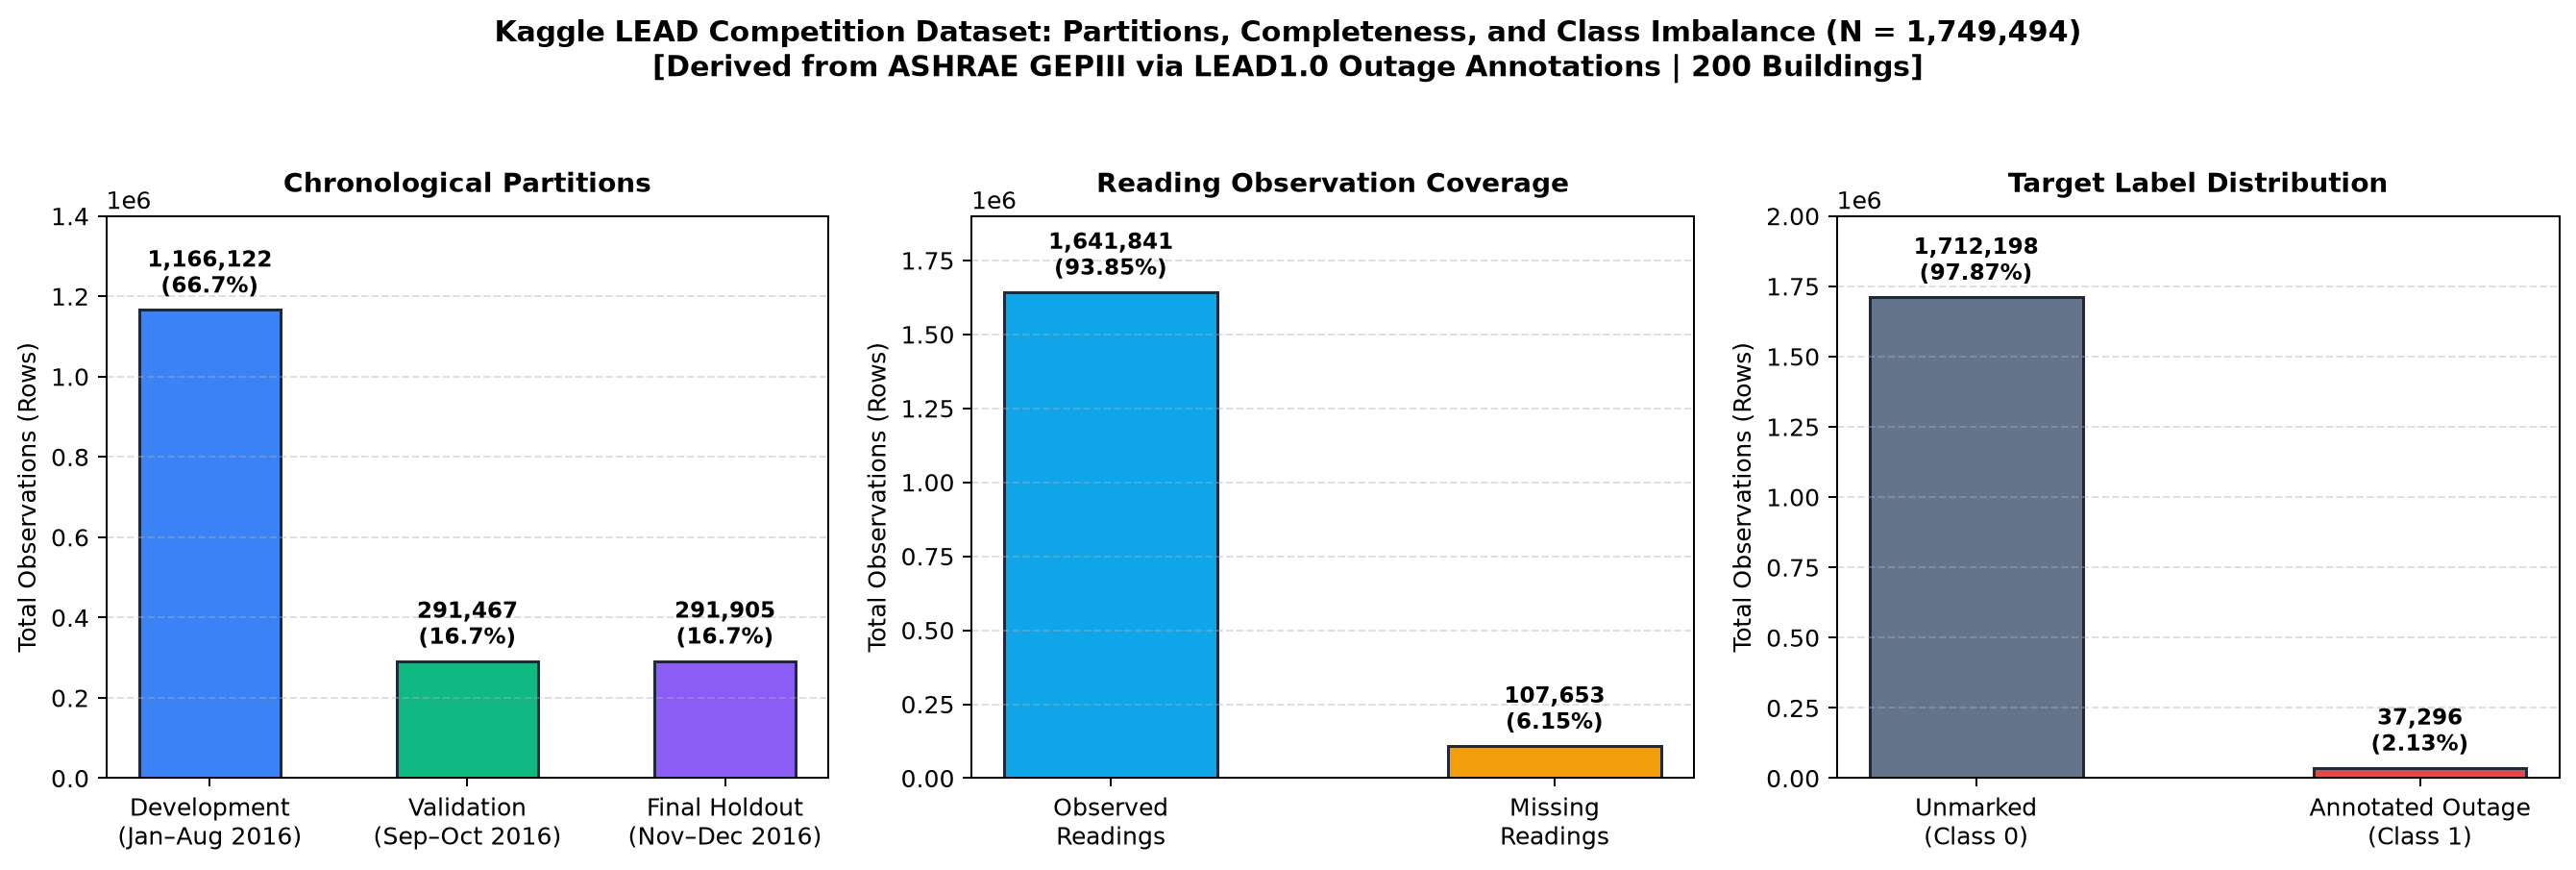

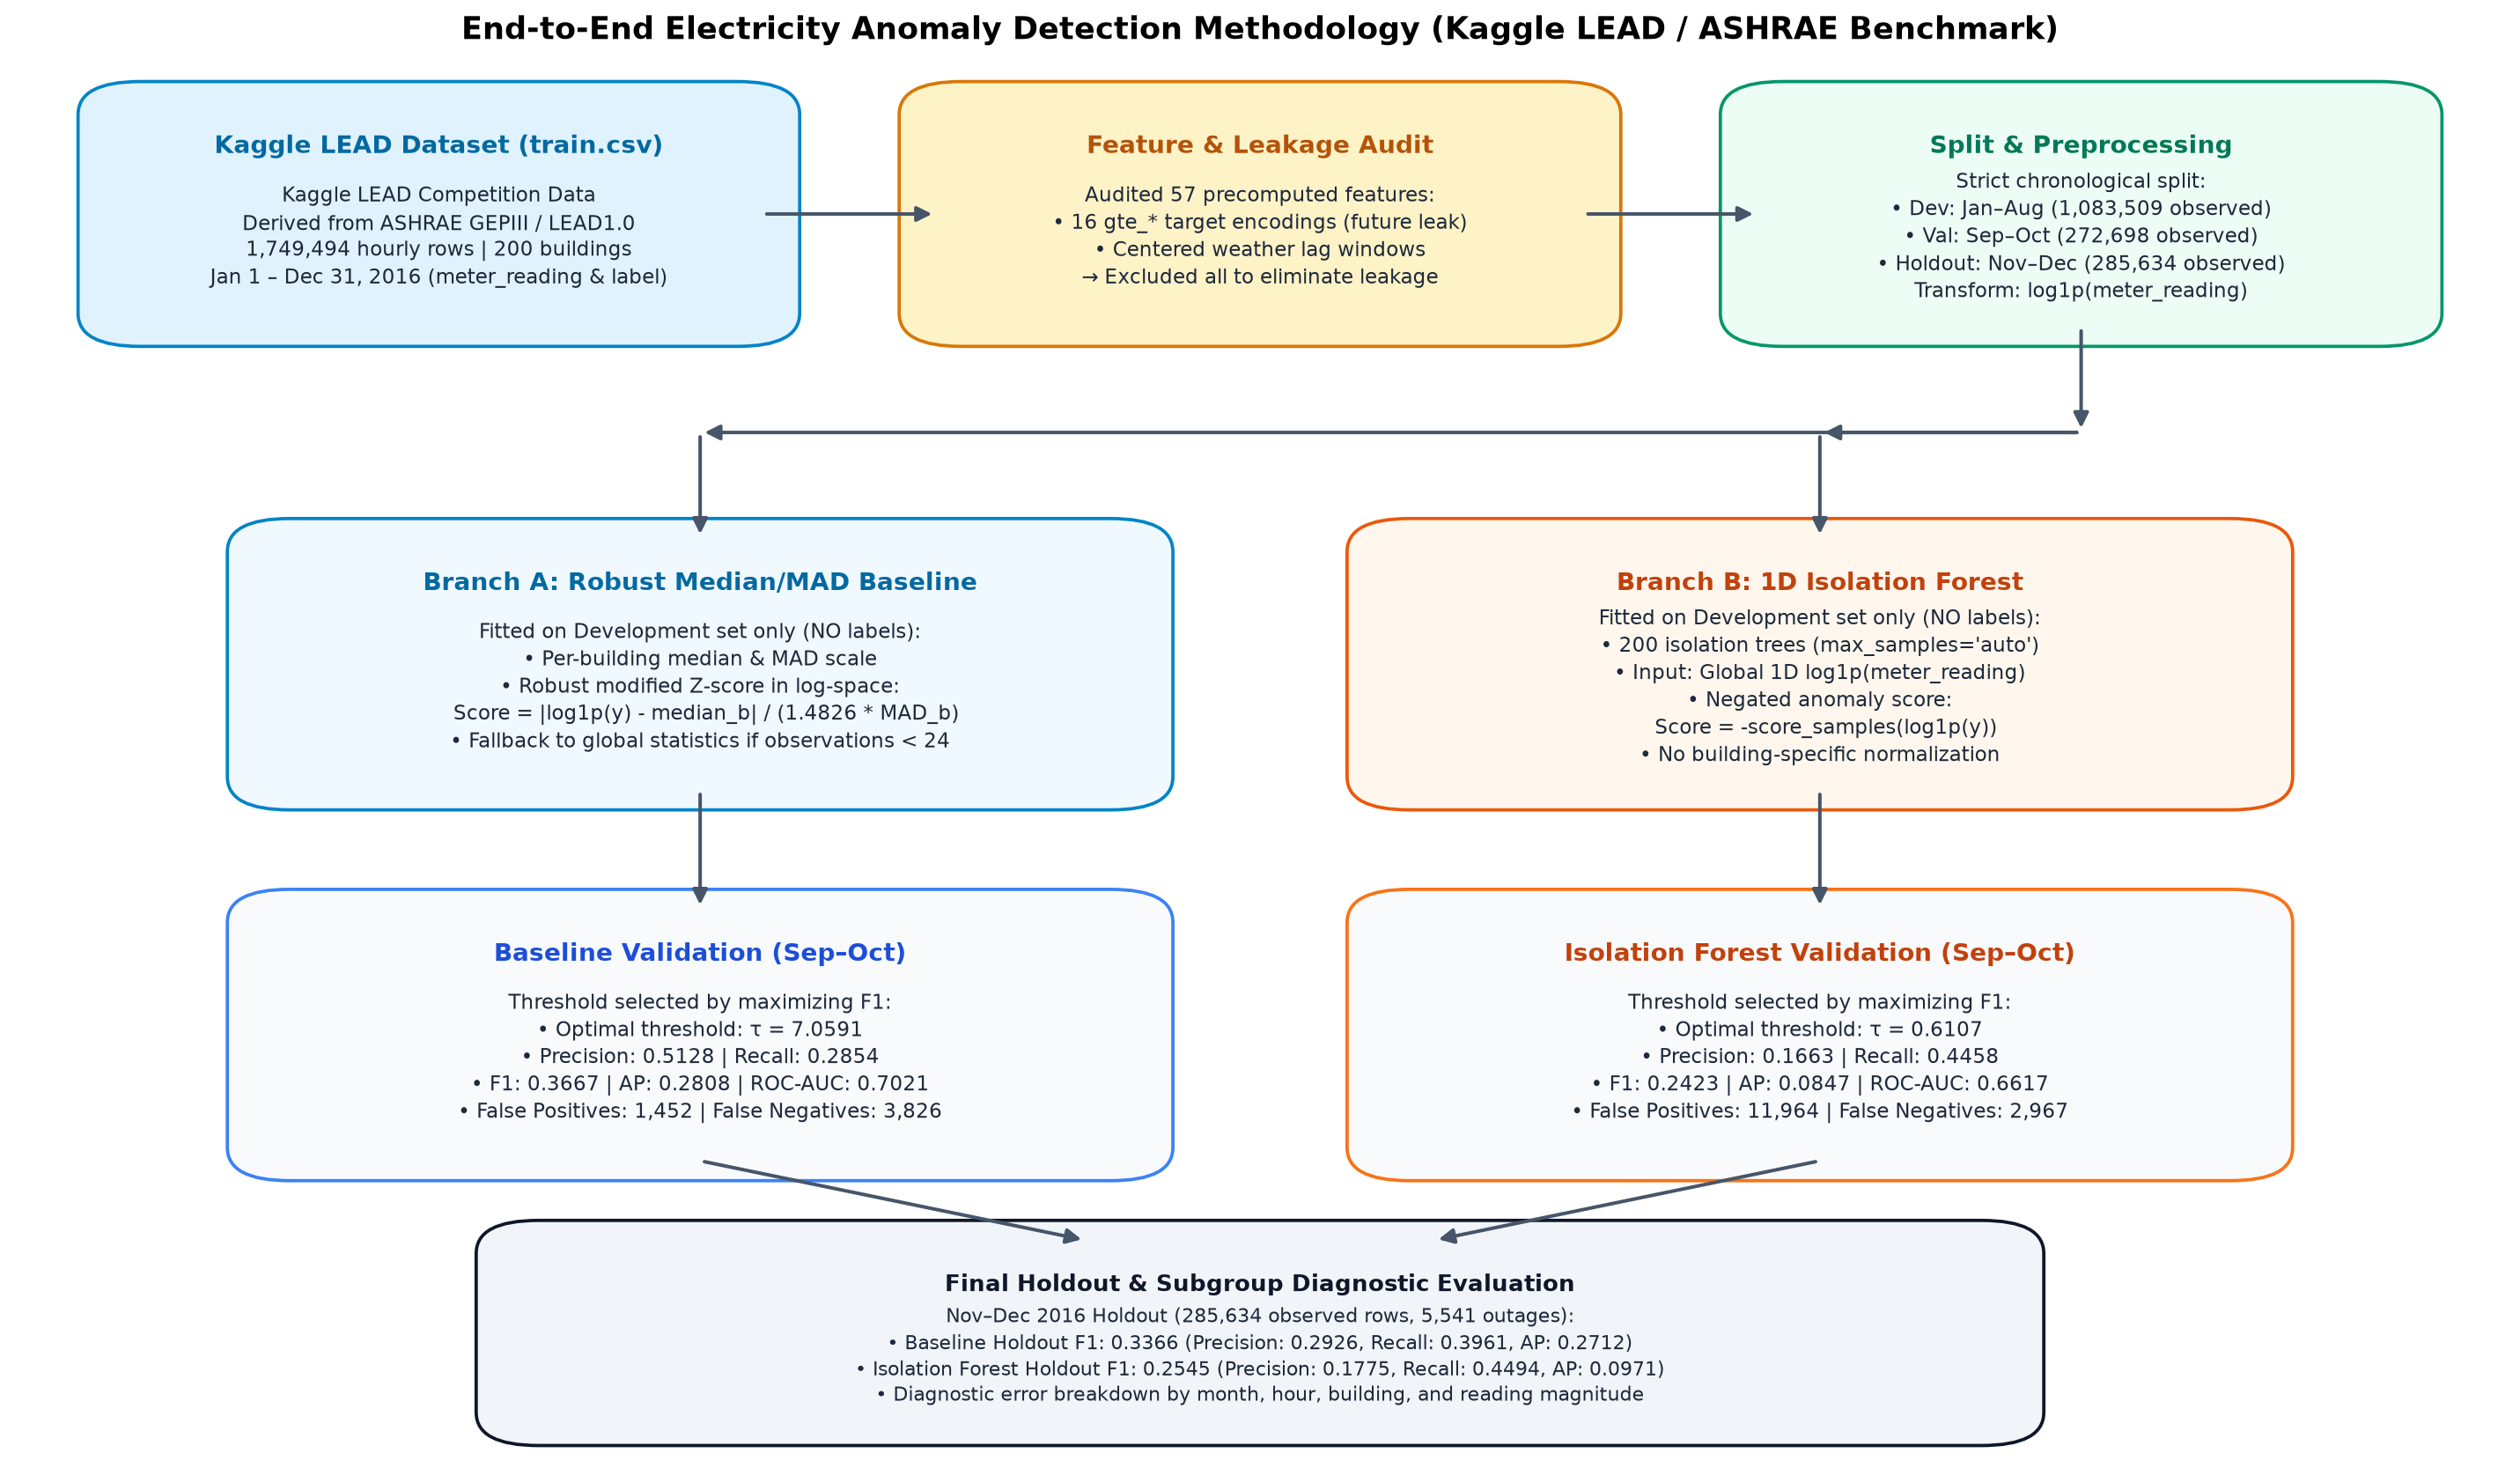

In [8]:
# Dataset Overview and Experimental Methodology Flowchart
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

figures_dir = Path("figures")
if (figures_dir / "dataset_overview.png").exists():
    img1 = Image.open(figures_dir / "dataset_overview.png")
    plt.figure(figsize=(15, 5))
    plt.imshow(img1)
    plt.axis("off")
    plt.show()

if (figures_dir / "methodology_flowchart.png").exists():
    img2 = Image.open(figures_dir / "methodology_flowchart.png")
    plt.figure(figsize=(16, 9.5))
    plt.imshow(img2)
    plt.axis("off")
    plt.show()


## Step 2: Report-Ready Dataset and Experimental-Design Notes

These notes summarize checks run against the CSV files in the project workspace. They are project notes for the eventual **Resources** and **Work Done** sections, not the final report. No anomaly-detection model has been trained.

### Dataset description and resources

| File | Verified shape | Observed columns and types | Role / limitation |
|---|---:|---|---|
| `train.csv` | 1,749,494 x 4 | `building_id` integer, `timestamp` text, `meter_reading` float, `anomaly` integer | Raw labelled observations by filename/schema. Local documentation does not define the label semantics. |
| `test.csv` | 1,800,567 x 4 | `row_id` integer, `building_id` integer, `timestamp` text, `meter_reading` float | Test observations; 94,864 meter readings (5.2686%) are missing. |
| `train_features.csv` | 1,749,494 x 57 | Numeric and string fields; includes raw source columns and engineered/weather/context fields | Precomputed feature table. Provenance is not present in this workspace. |
| `test_features.csv` | 1,800,567 x 57 | Same 57-column count; contains `row_id`, not `anomaly` | Precomputed test features; provenance is unverified. |
| `sample_submission.csv` | 1,800,567 x 2 | `row_id`, `anomaly` | Submission-shaped file; it is not evidence of model predictions or performance. |

Feature-file fields include building/site descriptors, weather values, lagged weather summaries, calendar fields, string-valued building/time combinations, and 16 `gte_`-prefixed numeric fields. Names alone do not establish their definitions. In chunked comparisons, all raw shared columns matched their feature-file counterparts at the same row positions: zero mismatches for train (`building_id`, `timestamp`, `meter_reading`, `anomaly`) and test (`row_id`, `building_id`, `timestamp`, `meter_reading`). Thus, the existing data can be referenced by row position, but a join is unnecessary and should not be guessed.

### Data-quality and missing-reading findings

- Training `meter_reading` is missing for 107,653 of 1,749,494 rows (6.1534%); train features have the same missing values in the same rows. Test has 94,864 missing readings (5.2686%).
- A full chunked scan found that `meter_reading` is the only feature-file column with missing values; its count and percentage match raw train. Missingness varies in time: monthly training rates range from 1.89% (November) to 10.65% (March). It varies substantially by building: 177/200 buildings have at least one missing reading, and the highest observed building rate is 61.59%.
- The provided training labels are 1,712,198 zeros (97.86818%) and 37,296 ones (2.13182%). In the inspected data, all 107,653 missing readings have label 0, while none of the rows labelled 1 have missing readings. This association is confirmed; its cause is unknown. It may reflect how labels or records were produced, so results on observed readings describe only the observed-reading subset and must be interpreted with this selection caveat.
- There are no missing `building_id` or timestamp values, no unparseable timestamps, no exact duplicate rows, and no repeated `(building_id, timestamp)` keys. The parsed time range is 2016-01-01 00:00 through 2016-12-31 23:00, with 8,784 unique hourly timestamps. Per-building row coverage ranges from 7,471 to 8,784 timestamps.
- Retain rows and leave missing readings missing at this stage. For reading-based models, later comparisons should use identical observed-reading masks and report the omitted/missing coverage. This is not a claim that missingness is random, and a reading-only detector cannot detect a missing reading as an anomaly.

### Preprocessing, feature-selection, and leakage decisions

The Step 2 code parses timestamps into a separate `timestamp_parsed` column and sorts chronologically while preserving source row identity. It does not alter the raw timestamp, labels, or readings. `anomaly` is kept separately as `evaluation_labels`; `row_id`, identifiers, timestamps, and unverified derived fields are excluded from model predictors.

No label definition, feature-generation script, or feature-provenance documentation is present locally. Therefore, lagged/weather fields, building/time aggregates, and all `gte_` fields are **uncertain and excluded**, not declared safe. The `anomaly` field appears in training features and is explicitly unsafe as a predictor. Recompute any needed calendar fields from the parsed timestamp in a later, separately reviewed change; do not rely on the precomputed versions without verifying their definitions. The cause of the observed label/missingness association is also unresolved.

### Evaluation protocol and next-experiment input

| Partition | Exact timestamp interval | Rows | Non-missing readings | Purpose |
|---|---|---:|---:|---|
| Development/training | 2016-01-01 00:00 through 2016-08-31 23:00 | 1,166,122 | 1,083,509 | Fit any detector and learned preprocessing. |
| Validation | 2016-09-01 00:00 through 2016-10-31 23:00 | 291,467 | 272,698 | Compare approaches and select a threshold using training labels only for evaluation/selection. |
| Final holdout | 2016-11-01 00:00 through 2016-12-31 23:00 | 291,905 | 285,634 | Preserve until decisions are fixed; use once for final evaluation. |

The boundaries use full calendar months within the observed 2016 range and create a forward-in-time test. They evaluate later periods for buildings also present in development, not generalization to unseen buildings. All 200 buildings occur in each interval, but 2 buildings in validation and 1 in the final holdout have no observed readings; keep their rows in metadata and report their missing coverage. Future comparisons should use the same observed-reading validation and final-holdout observations. Fit all learned preprocessing on development/training only. The label has not been confirmed as ground truth by local documentation, so label-based evaluation is conditional on that unresolved interpretation.

The prepared raw predictor set is exactly **`["meter_reading"]`**. `building_id` is available only as grouping metadata, not as a numeric predictor; parsed timestamp/source index are metadata; `anomaly` is evaluation-only; `row_id` and all unverified feature-file columns are excluded. For an initial statistical baseline and Isolation Forest, compare within-building behavior or use a per-building model/normalization learned from development observations; a single global raw-reading distribution could mistake between-building scale differences for anomalies. This is a design recommendation, not an experiment result.

### Report-template status and unresolved blockers

This work supplies verified facts for **Resources** (files, dimensions, tools and data limitations) and **Work Done** (data description, data-quality checks, preprocessing decisions, leakage controls and evaluation design). Method comparisons, figures/error plots, final architecture, results, literature survey, GitHub location and future-work conclusions remain unfilled because no models, report sources, plots, or repository URL have been established in this workspace. Do not invent them.

Before trusting later model results, investigate the definition/source of `anomaly`, the provenance and time availability of precomputed features (especially lagged, aggregate and `gte_` fields), and the strong observed association between missing readings and label values.

## Verified Dataset Identity and Multi-Tier Provenance

A rigorous, project-wide dataset source audit established the exact identity and multi-tier provenance of the experimental data:

1. **Immediate Experimental Package & Distribution:** Kaggle Community Prediction Competition: [Large-scale Energy Anomaly Detection (LEAD)](https://www.kaggle.com/competitions/energy-anomaly-detection/overview), hosted by **Pandarasamy Arjunan (Samy)** and **Manoj Gulati**. The competition packaged `train.csv` (1,749,494 hourly rows across 200 labeled commercial buildings for year 2016), `test.csv` (1,800,567 rows across 206 buildings), `train_features.csv` (57 precomputed columns), `test_features.csv` (57 columns), and `sample_submission.csv`.
2. **Academic Research Benchmark & Outage Annotation Layer:** [LEAD1.0: A Large-scale Annotated Dataset for Energy Anomaly Detection in Commercial Buildings](https://arxiv.org/abs/2203.17256) (Manoj Gulati and Pandarasamy Arjunan, arXiv:2203.17256, 2022; codebase: [samy101/lead-dataset](https://github.com/samy101/lead-dataset)). Gulati and Arjunan created an R Shiny annotation application (`AnomalyAnnotator/combine_anomaly.R`) to manually and semi-automatically tag logged power outage intervals (`outage_indices`). In this benchmark, positive flags (`1`) designate logged power outages, while class `0` designates observations not tagged as outages (unmarked observations, not independently certified normal operation).
3. **Upstream Physical Meter Readings & Weather Telemetry:** [ASHRAE Great Energy Predictor III (GEPIII)](https://www.kaggle.com/c/ashrae-energy-prediction/) competition (2019). The raw meter readings, building IDs, square footage, primary use, and weather observations originate upstream from ASHRAE GEPIII commercial campus facilities.
4. **Unsupported and Disproven Sources:** The dataset did **not** originate from the UCI Machine Learning Repository (which hosts individual French residential or Portuguese client load profiles). Furthermore, citing 'ASHRAE' alone is incomplete and misleading because raw ASHRAE GEPIII contains zero anomaly labels; the ground-truth outage labels originate exclusively from the LEAD annotation protocol. Additionally, this project evaluates the specific 200-building Kaggle competition subset on **hourly per-reading timestamps**, distinct from the full LEAD1.0 paper which evaluates daily 24-hour profile vectors across 1,413 buildings.

### Feature Provenance and Data Leakage Audit

There is no local feature-generation script or manifest. A published ASHRAE preprocessing pipeline has matching feature names, and the [LEAD winning-solution repository](https://github.com/buds-lab/LEAD-1st-solution) consumes these competition feature files from `../input/energy-anomaly-detection/`. In the matching [preprocessor](https://github.com/buds-lab/ashrae-great-energy-predictor-3-solution-analysis/blob/6cb180f2dbc6d33afb2b8b1fb0dbb369f62fd634/solutions/rank-1/scripts/02_preprocess_data_new.py), calendar features are derived from timestamps and metadata is merged by building ID. However, weather missing values are interpolated in both time directions; the 8 `air_temperature_*_lag7/73` columns use centered rolling windows (their `max`/`min` values are actually 95th/5th percentiles); and the 16 `gte_*` columns encode `log1p(meter_reading)` using group statistics fitted on the full training period and then applied to those same rows. The `gte_*` code uses meter readings, not anomaly labels, but leaks future-period and same-row information under this chronological split. Treat lagged weather and `gte_*` as **unsafe**; weather is **unresolved** row-by-row because imputed values may use future observations. Calendar/static metadata are **verified safe** under the matching formulas; building/time interaction fields are temporally safe but identifier-like and excluded from the initial experiment.

A chunked scan of all 1,749,494 training rows confirmed 107,653 missing readings (6.1534%); all carry label 0, none carry label 1, and `train_features.csv` preserves the raw missing-reading mask. The source code does not explain this association: its cleaning routine modifies a separate `clean_meter_reading` field. Do not impute or interpret missing readings as normal. Excluding them from reading-based evaluation removes only negatives, changes class prevalence, and limits conclusions to observed-reading rows.

Keep the existing split: development Jan-Aug 2016, validation Sep-Oct 2016, and final holdout Nov-Dec 2016. For the first baseline and Isolation Forest comparison, use only non-missing contemporaneous `meter_reading`; keep `anomaly` evaluation-only, exclude identifiers and unsafe/unresolved features, fit learned preprocessing on development only, and use identical observed validation rows. Do not use final-holdout labels for model or threshold selection.

References: [Kaggle LEAD Competition Overview](https://www.kaggle.com/competitions/energy-anomaly-detection/overview), [LEAD dataset and annotation code](https://github.com/samy101/lead-dataset), [LEAD1.0 paper (arXiv:2203.17256)](https://arxiv.org/abs/2203.17256), [ASHRAE GEPIII Preprocessing Pipeline](https://github.com/buds-lab/ashrae-great-energy-predictor-3-solution-analysis/blob/6cb180f2dbc6d33afb2b8b1fb0dbb369f62fd634/solutions/rank-1/scripts/02_preprocess_data_new.py), [LEAD 1st Place Solution Repository](https://github.com/buds-lab/LEAD-1st-solution).

## Step 3: Reading-Only Statistical Baseline and Isolation Forest

Use only observed, non-negative `meter_reading` values with `log1p`. `anomaly` is never supplied to either unsupervised fit; it is used only for validation threshold selection and evaluation. These labels are recorded outage annotations, and label 0 is not necessarily independently verified normal consumption. Both models are fitted on January-August development data only. Each score threshold is selected by maximizing validation F1, with ties preferring the higher threshold. November-December holdout labels are not read until the final cell. Missing readings are excluded and coverage is reported.

In [13]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import IsolationForest

# Reuse the loaded raw frame; otherwise read only the four raw training columns.
if "train_df" in globals() and {"building_id", "timestamp", "meter_reading", "anomaly"}.issubset(train_df.columns):
    experiment_source = train_df[["building_id", "timestamp", "meter_reading", "anomaly"]].copy()
elif "prepared_train" in globals() and {"building_id", "timestamp", "meter_reading", "anomaly"}.issubset(prepared_train.columns):
    experiment_source = prepared_train[["building_id", "timestamp", "meter_reading", "anomaly"]].copy()
else:
    experiment_root = Path(globals().get("project_dir", Path.cwd()))
    experiment_path = experiment_root / "train.csv"
    if not experiment_path.exists():
        experiment_path = Path.cwd() / "train.csv"
    if not experiment_path.exists():
        raise FileNotFoundError(f"Raw training file not found: {experiment_path.resolve()}")
    experiment_source = pd.read_csv(experiment_path, usecols=["building_id", "timestamp", "meter_reading", "anomaly"])

experiment_data = experiment_source.copy()
experiment_data["source_row_index"] = np.arange(len(experiment_data))
experiment_data["timestamp_parsed"] = pd.to_datetime(experiment_data["timestamp"], errors="coerce")
if experiment_data["timestamp_parsed"].isna().any():
    raise ValueError("Invalid or missing timestamps found; resolve before modeling.")
numeric_reading = pd.to_numeric(experiment_data["meter_reading"], errors="coerce")
invalid = experiment_data["meter_reading"].notna() & numeric_reading.isna()
if invalid.any():
    raise ValueError(f"Found {int(invalid.sum())} non-numeric, non-missing meter readings.")
observed_values = numeric_reading.dropna().to_numpy(dtype=float)
if not np.isfinite(observed_values).all():
    raise ValueError("Infinite readings found; resolve before log1p.")
if (observed_values < 0).any():
    raise ValueError(f"Found {int((observed_values < 0).sum())} negative readings; none were changed.")
experiment_data["meter_reading"] = numeric_reading
experiment_data = experiment_data.sort_values(
    ["timestamp_parsed", "building_id", "source_row_index"], kind="mergesort"
).reset_index(drop=True)

dev_start, val_start, holdout_start, end_exclusive = map(
    pd.Timestamp, ["2016-01-01", "2016-09-01", "2016-11-01", "2017-01-01"]
)
partition_masks = {
    "development": (experiment_data["timestamp_parsed"] >= dev_start) & (experiment_data["timestamp_parsed"] < val_start),
    "validation": (experiment_data["timestamp_parsed"] >= val_start) & (experiment_data["timestamp_parsed"] < holdout_start),
    "final_holdout": (experiment_data["timestamp_parsed"] >= holdout_start) & (experiment_data["timestamp_parsed"] < end_exclusive),
}
partition_count = sum(int(mask.sum()) for mask in partition_masks.values())
overlaps = sum(int((partition_masks[a] & partition_masks[b]).sum()) for a, b in [
    ("development", "validation"), ("development", "final_holdout"), ("validation", "final_holdout")
])
if partition_count != len(experiment_data) or overlaps:
    raise ValueError("Date partitions must cover every row exactly once without overlap.")
observed_mask = experiment_data["meter_reading"].notna()
coverage_table = pd.DataFrame([
    {"all_rows": int(mask.sum()), "observed_readings": int((mask & observed_mask).sum()),
     "excluded_missing": int((mask & ~observed_mask).sum()),
     "coverage_percent": 100 * (mask & observed_mask).sum() / mask.sum()}
    for mask in partition_masks.values()
], index=partition_masks.keys())
display(coverage_table.round(2))

development_rows = experiment_data.loc[partition_masks["development"] & observed_mask].copy()
validation_rows = experiment_data.loc[partition_masks["validation"] & observed_mask].copy()
if development_rows.empty or validation_rows.empty:
    raise ValueError("Development and validation must each contain observed readings.")
development_log = np.log1p(development_rows["meter_reading"].to_numpy()).reshape(-1, 1)
validation_log = np.log1p(validation_rows["meter_reading"].to_numpy()).reshape(-1, 1)
validation_labels = validation_rows["anomaly"].to_numpy(dtype=int)  # evaluation/threshold selection only

# Use per-building median/MAD; sparse or zero-MAD groups fall back to global dev statistics.
MIN_BUILDING_OBSERVATIONS = 24
development_stats = development_rows.assign(log_reading=development_log[:, 0]).groupby("building_id")["log_reading"].agg(
    count="count", median="median", mad=lambda values: np.median(np.abs(values - np.median(values)))
)
global_median = float(np.median(development_log[:, 0]))
global_mad = float(np.median(np.abs(development_log[:, 0] - global_median)))
global_scale = 1.4826 * global_mad or 1.0
supported = development_stats["count"] >= MIN_BUILDING_OBSERVATIONS
building_centers = development_stats["median"].where(supported, global_median)
local_scales = 1.4826 * development_stats["mad"]
building_scales = local_scales.where(local_scales > 0, global_scale).where(supported, global_scale)

def robust_baseline_scores(rows, log_values):
    centers = rows["building_id"].map(building_centers).fillna(global_median).to_numpy()
    scales = rows["building_id"].map(building_scales).fillna(global_scale).to_numpy()
    return np.abs(log_values[:, 0] - centers) / scales

validation_baseline_scores = robust_baseline_scores(validation_rows, validation_log)

# The detector sees only development readings; contamination is not label-derived.
ISOLATION_FOREST_PARAMETERS = {
    "n_estimators": 200, "max_samples": "auto", "contamination": "auto",
    "random_state": 42, "n_jobs": -1,
}
isolation_forest = IsolationForest(**ISOLATION_FOREST_PARAMETERS)
isolation_forest.fit(development_log)
validation_iforest_scores = -isolation_forest.score_samples(validation_log)
assert len(validation_baseline_scores) == len(validation_iforest_scores) == len(validation_labels)
assert np.isfinite(validation_baseline_scores).all() and np.isfinite(validation_iforest_scores).all()
print(f"Development observed rows fitted: {len(development_rows):,}")
print(f"Validation observed rows: {len(validation_rows):,}")
print(f"Buildings using global baseline fallback: {int((~supported).sum()):,}; local MAD=0: {int((development_stats['mad'] == 0).sum()):,}")
print("Isolation Forest parameters:", ISOLATION_FOREST_PARAMETERS)
print("Both fits received only log1p(meter_reading), never anomaly labels or holdout rows.")

,all_rows,observed_readings,excluded_missing,coverage_percent
development,1166122,1083509,82613,92.92
validation,291467,272698,18769,93.56
final_holdout,291905,285634,6271,97.85


Development observed rows fitted: 1,083,509
Validation observed rows: 272,698
Buildings using global baseline fallback: 0; local MAD=0: 0
Isolation Forest parameters: {'n_estimators': 200, 'max_samples': 'auto', 'contamination': 'auto', 'random_state': 42, 'n_jobs': -1}
Both fits received only log1p(meter_reading), never anomaly labels or holdout rows.


In [14]:
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)

def choose_f1_threshold(labels, scores):
    """Choose a high-score-is-anomaly threshold using validation labels only."""
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    if not thresholds.size:
        raise ValueError("Threshold selection needs at least two distinct validation scores.")
    denominator = precision[:-1] + recall[:-1]
    f1_values = np.divide(2 * precision[:-1] * recall[:-1], denominator,
                          out=np.zeros_like(denominator), where=denominator > 0)
    tied = np.flatnonzero(np.isclose(f1_values, f1_values.max()))
    chosen = tied[np.argmax(thresholds[tied])]  # fewer alerts when F1 ties
    return float(thresholds[chosen])

if not set(np.unique(validation_labels)).issubset({0, 1}):
    raise ValueError("Validation labels must be binary 0/1 for evaluation.")

def calculate_metrics(labels, scores, threshold):
    predictions = (scores >= threshold).astype(int)
    two_classes = np.unique(labels).size == 2
    return {
        "threshold": threshold,
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores) if two_classes else np.nan,
        "average_precision_pr_auc": average_precision_score(labels, scores) if two_classes else np.nan,
        "confusion_matrix": confusion_matrix(labels, predictions, labels=[0, 1]),
        "predictions": predictions,
    }

validation_scores = {
    "Robust per-building median/MAD": validation_baseline_scores,
    "Isolation Forest": validation_iforest_scores,
}
validation_thresholds, validation_results = {}, {}
for model_name, scores in validation_scores.items():
    threshold = choose_f1_threshold(validation_labels, scores)
    validation_thresholds[model_name] = threshold
    validation_results[model_name] = calculate_metrics(validation_labels, scores, threshold)
validation_comparison = pd.DataFrame({
    name: {key: value for key, value in result.items() if key not in {"confusion_matrix", "predictions"}}
    for name, result in validation_results.items()
}).T
print(f"Validation rows: {len(validation_labels):,}; outage labels: {int(validation_labels.sum()):,} "
      f"({100 * validation_labels.mean():.3f}%). Threshold rule: score >= threshold predicts outage.")
display(validation_comparison.round(4))
for name, result in validation_results.items():
    print(f"{name} confusion matrix [[TN, FP], [FN, TP]]:")
    display(pd.DataFrame(result["confusion_matrix"], index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))

Validation rows: 272,698; outage labels: 5,354 (1.963%). Threshold rule: score >= threshold predicts outage.


,threshold,precision,recall,f1,roc_auc,average_precision_pr_auc
Robust per-building median/MAD,7.0591,0.5128,0.2854,0.3667,0.7021,0.2808
Isolation Forest,0.6107,0.1663,0.4458,0.2423,0.6617,0.0847


Robust per-building median/MAD confusion matrix [[TN, FP], [FN, TP]]:


,Predicted 0,Predicted 1
Actual 0,265892,1452
Actual 1,3826,1528


Isolation Forest confusion matrix [[TN, FP], [FN, TP]]:


,Predicted 0,Predicted 1
Actual 0,255380,11964
Actual 1,2967,2387


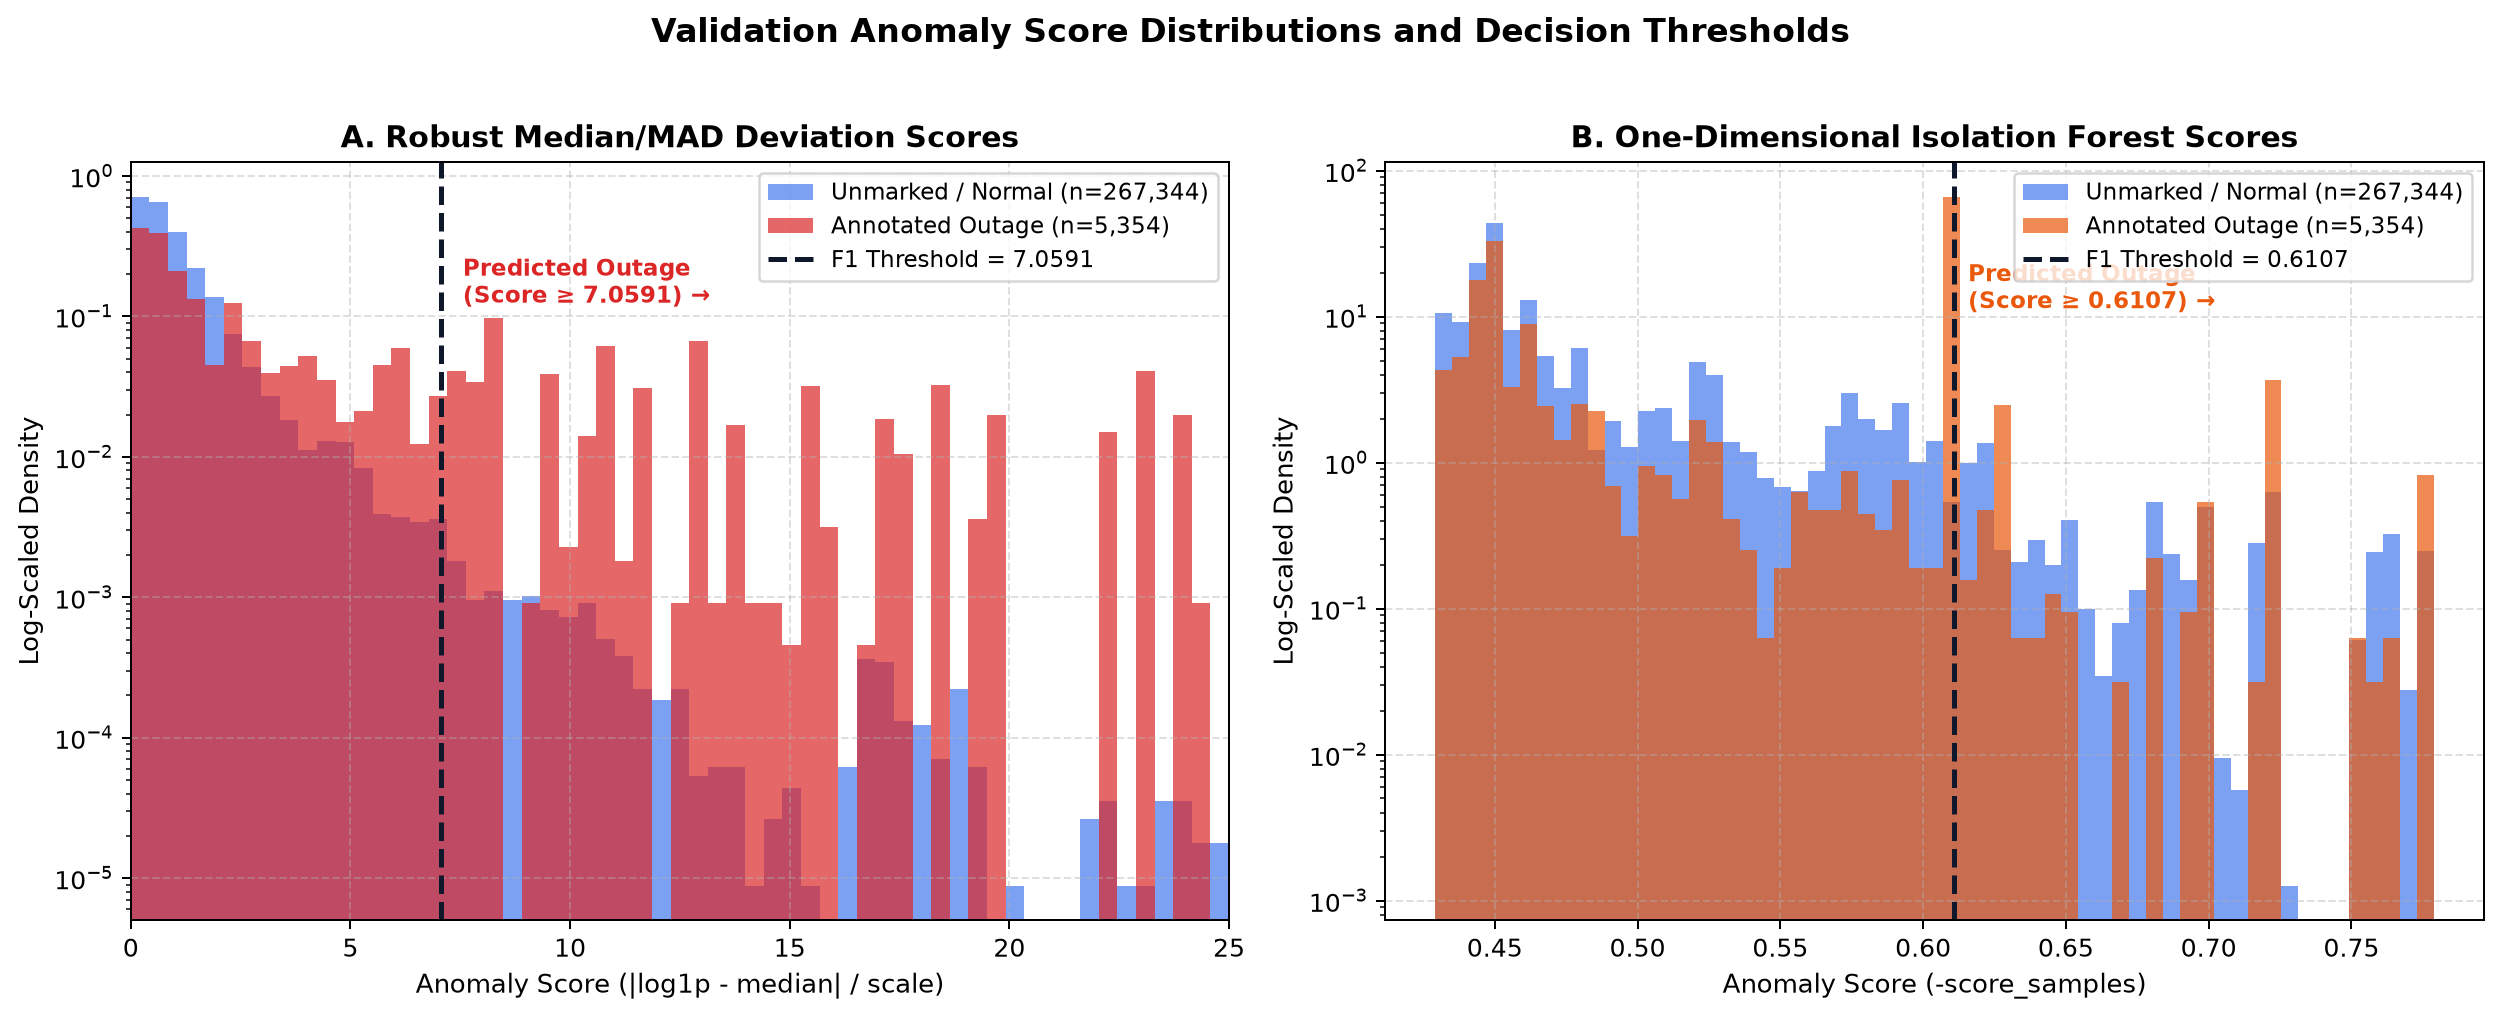

In [12]:
# Visualizing Anomaly Score Distributions and Decision Thresholds
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

normal_base_scores = validation_baseline_scores[validation_labels == 0]
outage_base_scores = validation_baseline_scores[validation_labels == 1]
base_th = validation_thresholds["Robust per-building median/MAD"]

bins_base = np.linspace(0, 25, 60)
ax1.hist(normal_base_scores, bins=bins_base, alpha=0.6, color="#2563eb", density=True, label=f"Unmarked / Normal (n={len(normal_base_scores):,})", log=True)
ax1.hist(outage_base_scores, bins=bins_base, alpha=0.7, color="#dc2626", density=True, label=f"Annotated Outage (n={len(outage_base_scores):,})", log=True)
ax1.axvline(base_th, color="#0f172a", linestyle="--", linewidth=2, label=f"F1 Threshold = {base_th:.4f}")

ax1.set_title("A. Robust Median/MAD Deviation Scores", fontsize=12, fontweight="bold")
ax1.set_xlabel("Anomaly Score (|log1p - median| / scale)", fontsize=10.5)
ax1.set_ylabel("Log-Scaled Density", fontsize=10.5)
ax1.set_xlim(0, 25)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(fontsize=9, loc="upper right")
ax1.text(base_th + 0.5, ax1.get_ylim()[1] * 0.1, f"Predicted Outage\n(Score ≥ {base_th:.4f}) →", color="#dc2626", fontweight="bold", fontsize=9)

normal_if_scores = validation_iforest_scores[validation_labels == 0]
outage_if_scores = validation_iforest_scores[validation_labels == 1]
if_th = validation_thresholds["Isolation Forest"]

bins_if = np.linspace(min(validation_iforest_scores), max(validation_iforest_scores), 60)
ax2.hist(normal_if_scores, bins=bins_if, alpha=0.6, color="#2563eb", density=True, label=f"Unmarked / Normal (n={len(normal_if_scores):,})", log=True)
ax2.hist(outage_if_scores, bins=bins_if, alpha=0.7, color="#ea580c", density=True, label=f"Annotated Outage (n={len(outage_if_scores):,})", log=True)
ax2.axvline(if_th, color="#0f172a", linestyle="--", linewidth=2, label=f"F1 Threshold = {if_th:.4f}")

ax2.set_title("B. One-Dimensional Isolation Forest Scores", fontsize=12, fontweight="bold")
ax2.set_xlabel("Anomaly Score (-score_samples)", fontsize=10.5)
ax2.set_ylabel("Log-Scaled Density", fontsize=10.5)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(fontsize=9, loc="upper right")
ax2.text(if_th + 0.005, ax2.get_ylim()[1] * 0.1, f"Predicted Outage\n(Score ≥ {if_th:.4f}) →", color="#ea580c", fontweight="bold", fontsize=9)

fig.suptitle("Validation Anomaly Score Distributions and Decision Thresholds", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(figures_dir / "validation_scores_threshold.png", dpi=180, bbox_inches="tight")
plt.show()


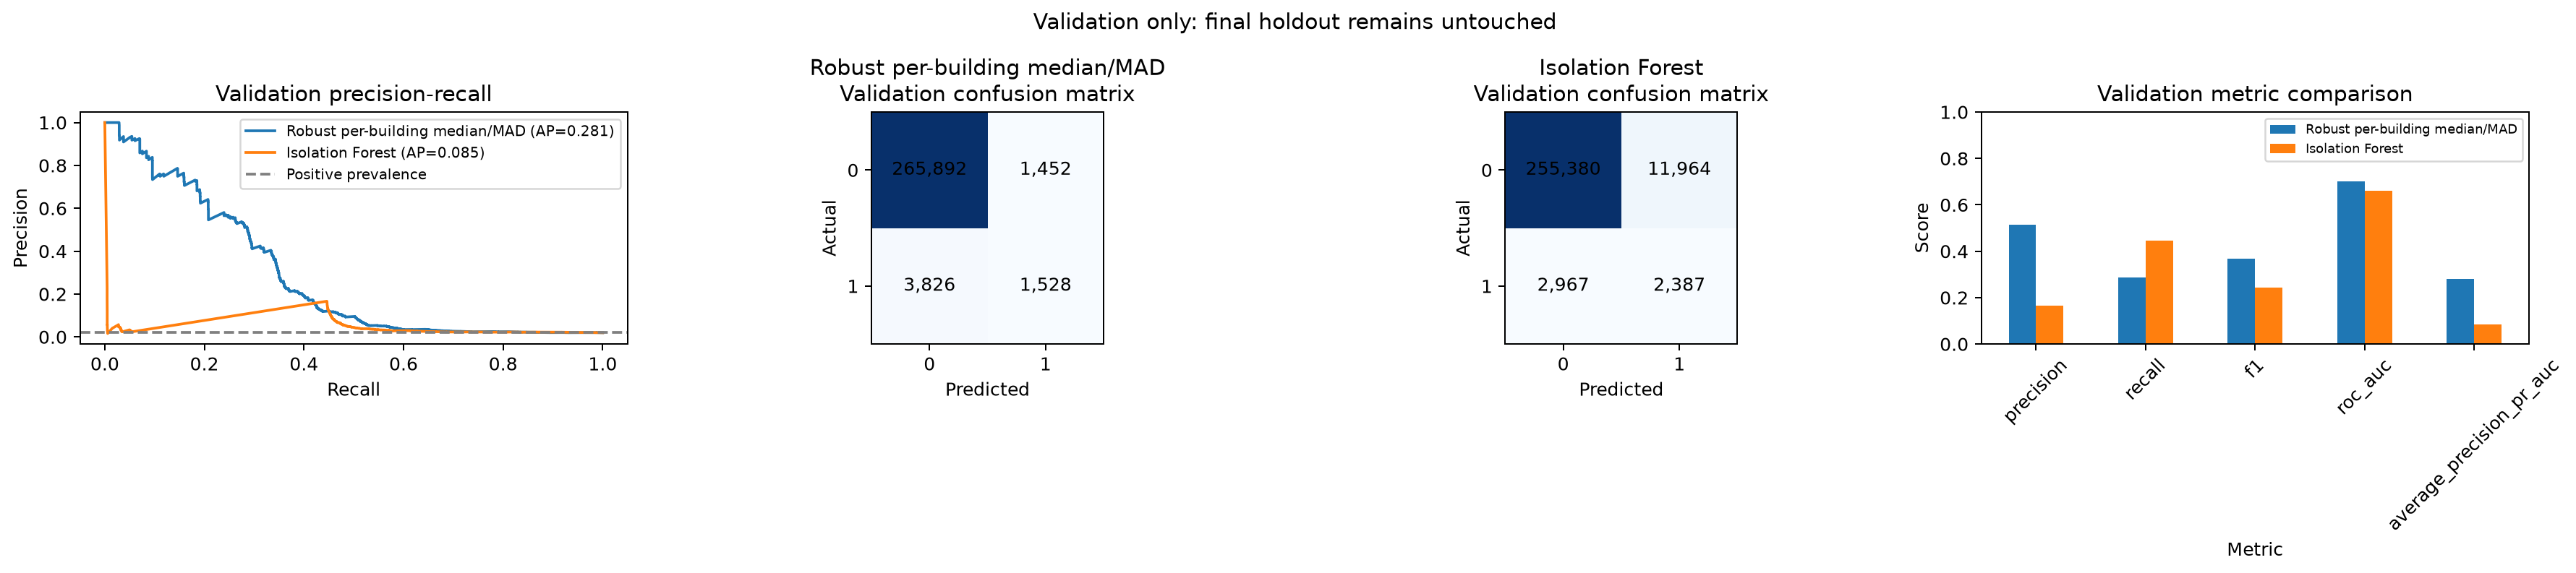

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for name, scores in validation_scores.items():
    precision_curve, recall_curve, _ = precision_recall_curve(validation_labels, scores)
    ap = validation_results[name]["average_precision_pr_auc"]
    axes[0].plot(recall_curve, precision_curve, label=f"{name} (AP={ap:.3f})")
axes[0].axhline(validation_labels.mean(), color="gray", linestyle="--", label="Positive prevalence")
axes[0].set(title="Validation precision-recall", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8)
for axis, name in zip(axes[1:3], validation_scores):
    matrix = validation_results[name]["confusion_matrix"]
    axis.imshow(matrix, cmap="Blues")
    axis.set(title=f"{name}\nValidation confusion matrix", xlabel="Predicted", ylabel="Actual", xticks=[0, 1], yticks=[0, 1])
    for (row, column), value in np.ndenumerate(matrix):
        axis.text(column, row, f"{value:,}", ha="center", va="center")
validation_comparison[["precision", "recall", "f1", "roc_auc", "average_precision_pr_auc"]].T.plot(kind="bar", ax=axes[3])
axes[3].set(title="Validation metric comparison", ylabel="Score", ylim=(0, 1), xlabel="Metric")
axes[3].tick_params(axis="x", labelrotation=45)
axes[3].legend(fontsize=7)
fig.suptitle("Validation only: final holdout remains untouched")
fig.tight_layout()
from pathlib import Path
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)
fig.savefig(figures_dir / "validation_model_diagnostics.png", dpi=180, bbox_inches="tight")

from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

pr_fig, pr_ax = plt.subplots(figsize=(7, 5))
for name, scores in validation_scores.items():
    precision, recall, _ = precision_recall_curve(validation_labels, scores)
    average_precision = validation_results[name]["average_precision_pr_auc"]
    pr_ax.plot(recall, precision, label=f"{name} (AP={average_precision:.3f})")
pr_ax.axhline(validation_labels.mean(), color="gray", linestyle=":", label="Positive prevalence")
pr_ax.set(title="Validation precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
pr_ax.legend()
pr_fig.tight_layout()
pr_fig.savefig(figures_dir / "validation_precision_recall.png", dpi=180, bbox_inches="tight")
plt.close(pr_fig)

cm_fig, cm_axes = plt.subplots(1, len(validation_results), figsize=(11, 4))
for axis, (name, result) in zip(np.atleast_1d(cm_axes), validation_results.items()):
    ConfusionMatrixDisplay(result["confusion_matrix"], display_labels=["Not marked", "Annotated outage"]).plot(
        ax=axis, values_format="d", colorbar=False
    )
    axis.set_title(f"{name}\nValidation threshold")
cm_fig.suptitle("Validation confusion matrices (rows=actual, columns=predicted)")
cm_fig.tight_layout()
cm_fig.savefig(figures_dir / "validation_confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.close(cm_fig)

comparison_fig, comparison_ax = plt.subplots(figsize=(9, 5))
validation_comparison[["precision", "recall", "f1", "roc_auc", "average_precision_pr_auc"]].rename(
    columns={"average_precision_pr_auc": "average_precision"}
).plot(kind="bar", ax=comparison_ax)
comparison_ax.set(title="Validation metric comparison", xlabel="Model", ylabel="Score", ylim=(0, 1))
comparison_ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
comparison_ax.tick_params(axis="x", labelrotation=0)
comparison_fig.tight_layout()
comparison_fig.savefig(figures_dir / "validation_model_comparison.png", dpi=180, bbox_inches="tight")
plt.close(comparison_fig)
plt.show()

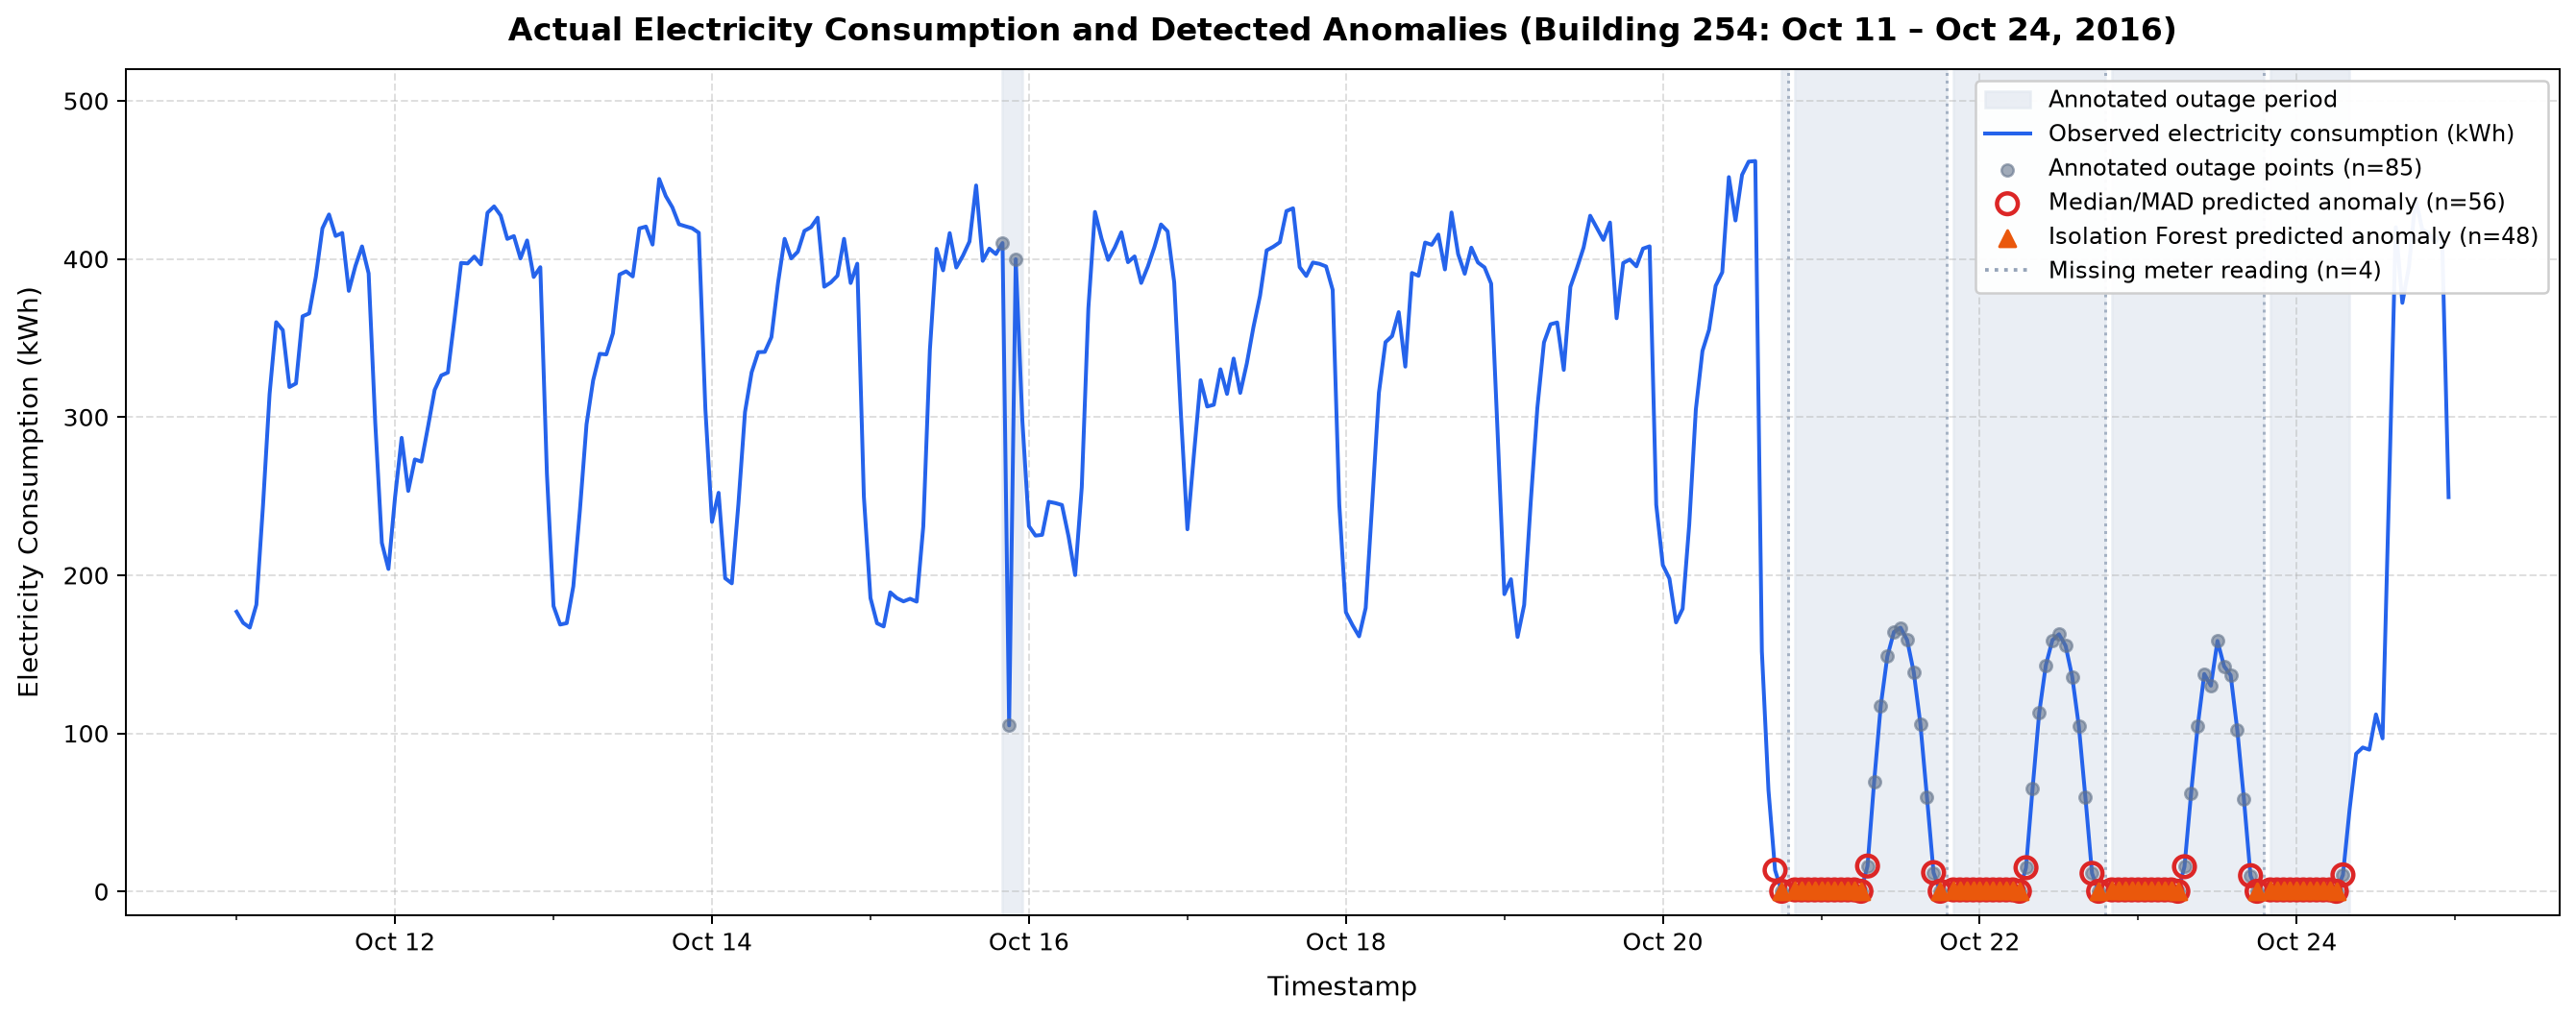

In [14]:
# Visualizing Actual Electricity Consumption with Detected Anomalies (Building 254: Oct 11 – Oct 24, 2016)
import matplotlib.dates as mdates

val_plot_df = validation_rows.copy()
val_plot_df["baseline_pred"] = validation_results["Robust per-building median/MAD"]["predictions"]
val_plot_df["iforest_pred"] = validation_results["Isolation Forest"]["predictions"]

b254 = val_plot_df[val_plot_df["building_id"] == 254].sort_values("timestamp_parsed").copy()
start_time = pd.Timestamp("2016-10-11 00:00:00")
end_time = pd.Timestamp("2016-10-25 00:00:00")

full_time_grid = pd.date_range(start=start_time, end=end_time - pd.Timedelta(hours=1), freq="1h")
grid_df = pd.DataFrame({"timestamp_parsed": full_time_grid})
merged = pd.merge(grid_df, b254, on="timestamp_parsed", how="left")

fig, ax = plt.subplots(figsize=(15, 6))

# Continuous outage period shading
in_block, block_start = False, None
for idx, row in merged.iterrows():
    if row["anomaly"] == 1 and not in_block:
        in_block = True
        block_start = row["timestamp_parsed"]
    elif row["anomaly"] != 1 and in_block:
        in_block = False
        ax.axvspan(block_start, row["timestamp_parsed"], color="#e2e8f0", alpha=0.7,
                   label="Annotated outage period" if "Annotated outage period" not in [l.get_label() for l in ax.get_lines() + ax.patches] else "")
if in_block:
    ax.axvspan(block_start, merged.iloc[-1]["timestamp_parsed"], color="#e2e8f0", alpha=0.7,
               label="Annotated outage period" if "Annotated outage period" not in [l.get_label() for l in ax.get_lines() + ax.patches] else "")

ax.plot(merged["timestamp_parsed"], merged["meter_reading"], color="#2563eb", linewidth=1.6, label="Observed electricity consumption (kWh)")

outages = merged[merged["anomaly"] == 1]
ax.scatter(outages["timestamp_parsed"], outages["meter_reading"], color="#64748b", marker="o", s=25, alpha=0.6, label=f"Annotated outage points (n={len(outages)})")

base_anoms = merged[merged["baseline_pred"] == 1]
ax.scatter(base_anoms["timestamp_parsed"], base_anoms["meter_reading"], facecolors="none", edgecolors="#dc2626", s=75, linewidth=1.8, marker="o", label=f"Median/MAD predicted anomaly (n={len(base_anoms)})")

if_anoms = merged[merged["iforest_pred"] == 1]
ax.scatter(if_anoms["timestamp_parsed"], if_anoms["meter_reading"], facecolors="#ea580c", edgecolors="#ea580c", s=45, linewidth=1.2, marker="^", label=f"Isolation Forest predicted anomaly (n={len(if_anoms)})")

missing = merged[merged["meter_reading"].isna()]
if not missing.empty:
    for _, m_row in missing.iterrows():
        ax.axvline(m_row["timestamp_parsed"], color="#94a3b8", linestyle=":", alpha=0.8, linewidth=1.2)
    ax.plot([], [], color="#94a3b8", linestyle=":", label=f"Missing meter reading (n={len(missing)})")

ax.set_title("Actual Electricity Consumption and Detected Anomalies (Building 254: Oct 11 – Oct 24, 2016)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Timestamp", fontsize=11, labelpad=8)
ax.set_ylabel("Electricity Consumption (kWh)", fontsize=11, labelpad=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_minor_locator(mdates.DayLocator(interval=1))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right", framealpha=0.95, fontsize=9.5)
ax.set_ylim(-15, 520)

fig.tight_layout()
fig.savefig(figures_dir / "validation_anomaly_detection_timeseries.png", dpi=180, bbox_inches="tight")
plt.show()


### Final holdout evaluation (run once, after validation decisions are fixed)

This next cell is the only experiment cell that reads final-holdout labels for scoring. Do not tune models, features, or thresholds after inspecting it; a later redesign needs a new untouched test period.

Holdout coverage: 285,634/291,905 observed (97.85%); 6,271 missing readings excluded.
Recorded outage labels: 5,541/285,634 (1.940%).


,threshold,precision,recall,f1,roc_auc,average_precision_pr_auc
Robust per-building median/MAD,7.0591,0.2926,0.3961,0.3366,0.7587,0.2712
Isolation Forest,0.6107,0.1775,0.4494,0.2545,0.6894,0.0971


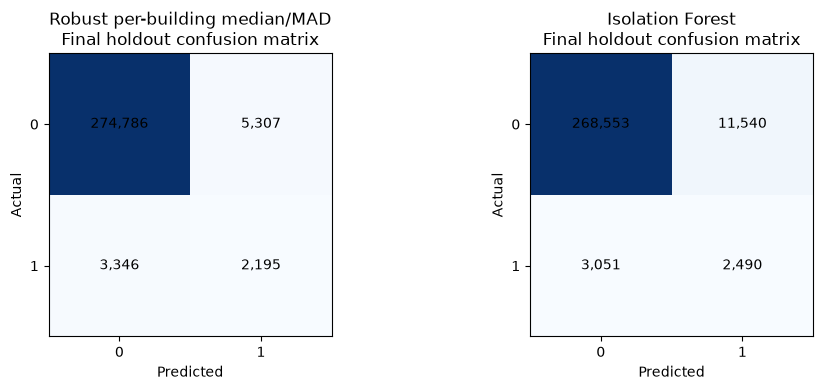

In [16]:
final_rows = experiment_data.loc[partition_masks["final_holdout"] & observed_mask].copy()
all_final_rows = int(partition_masks["final_holdout"].sum())
if final_rows.empty:
    raise ValueError("Final holdout has no observed readings to evaluate.")
final_log = np.log1p(final_rows["meter_reading"].to_numpy()).reshape(-1, 1)
final_scores = {
    "Robust per-building median/MAD": robust_baseline_scores(final_rows, final_log),
    "Isolation Forest": -isolation_forest.score_samples(final_log),
}
# Holdout labels are first read here, after validation thresholds are fixed.
final_labels = final_rows["anomaly"].to_numpy(dtype=int)
if not set(np.unique(final_labels)).issubset({0, 1}):
    raise ValueError("Final-holdout labels must be binary 0/1 for evaluation.")
final_results = {
    name: calculate_metrics(final_labels, scores, validation_thresholds[name])
    for name, scores in final_scores.items()
}
final_comparison = pd.DataFrame({
    name: {key: value for key, value in result.items() if key not in {"confusion_matrix", "predictions"}}
    for name, result in final_results.items()
}).T
print(f"Holdout coverage: {len(final_rows):,}/{all_final_rows:,} observed "
      f"({100 * len(final_rows) / all_final_rows:.2f}%); {all_final_rows - len(final_rows):,} missing readings excluded.")
print(f"Recorded outage labels: {int(final_labels.sum()):,}/{len(final_labels):,} "
      f"({100 * final_labels.mean():.3f}%).")
display(final_comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, (name, result) in zip(axes, final_results.items()):
    matrix = result["confusion_matrix"]
    axis.imshow(matrix, cmap="Blues")
    axis.set(title=f"{name}\nFinal holdout confusion matrix", xlabel="Predicted", ylabel="Actual", xticks=[0, 1], yticks=[0, 1])
    for (row, column), value in np.ndenumerate(matrix):
        axis.text(column, row, f"{value:,}", ha="center", va="center")
fig.tight_layout()
plt.show()

### Interpretation and limitations

Interpret metrics together with coverage: missing readings are excluded and all missing training readings were labeled 0, so evaluation applies only to observed readings and may be biased. Average precision is useful under class imbalance; ROC-AUC measures ranking, while precision, recall, F1 and confusion matrices depend on the selected threshold. The baseline falls back to global development statistics for buildings with insufficient history or zero MAD. Isolation Forest is one-dimensional and cannot represent daily, seasonal, or multi-feature context. Labels are outage annotations, and zero is not necessarily independently verified normal. Conclusions should be based only on executed output.

## Validation Error Analysis (Validation Rows Only)

This analysis uses the existing validation predictions and validation labels only. It does not refit either model, reselect thresholds, or inspect final-holdout labels. Error patterns by month, building, hour, and reading range are descriptive associations, not explanations of why an outage was annotated or why a detector erred. Here label 0 means not marked as an outage, not independently verified normal consumption.

Validation error counts and rates (label 0 is not guaranteed normal):
Monthly error counts and rates; rates use the month-specific actual-label denominator:
Hourly error summary (descriptive only):
Buildings with the most combined model errors; counts are descriptive, not causal:
Error counts/rates by validation log-reading quantile:
Validation label prevalence: 1.963%; an always-label-0 rule would be 98.037% accurate while detecting no annotated outages.


                                evaluated_rows  false_positives  false_positive_rate_among_label0  false_negatives  false_negative_rate_among_label1  true_negatives  true_positives
model                                                                                                                                                                               
Robust per-building median/MAD          272698             1452                            0.0054             3826                            0.7146          265892            1528
Isolation Forest                        272698            11964                            0.0448             2967                            0.5542          255380            2387

                                      false_positives  false_negatives  label0_rows  label1_rows  false_positive_rate  false_negative_rate
model                          month                                                                                                      
Isolation Forest               9                 5424             1369       135608         2083               0.0400               0.6572
                               10                6540             1598       131736         3271               0.0496               0.4885
Robust per-building median/MAD 9                  478             1782       135608         2083               0.0035               0.8555
                               10                 974             2044       131736         3271               0.0074               0.6249

                                     false_positives  false_negatives  label0_rows  label1_rows  false_positive_rate  false_negative_rate
model                          hour                                                                                                      
Isolation Forest               0                 433              165        11126          222               0.0389               0.7432
                               1                 395              116        11113          201               0.0355               0.5771
                               2                 379               97        11138          200               0.0340               0.4850
                               3                 374               88        11148          210               0.0335               0.4190
                               4                 374               89        11146          212               0.0336               0.4198
                               5  

                                            false_positives  false_negatives  label0_rows  label1_rows  false_positive_rate  false_negative_rate
model                          building_id                                                                                                      
Isolation Forest               1284                    1455                0         1455            7               1.0000               0.0000
                               356                     1446                0         1446           14               1.0000               0.0000
                               801                     1430                0         1430           31               1.0000               0.0000
                               345                     1406                0         1406           58               1.0000               0.0000
                               653                     1085                0         1464            0               0.7411       

                                                  rows  label0_rows  label1_rows  false_positives  false_negatives  false_positive_rate  false_negative_rate
model                          reading_range                                                                                                                
Isolation Forest               (0.00895, 3.178]  55072        52538         2534             5989              271               0.1140               0.1069
                               (3.178, 4.069]    54008        53371          637                0              637               0.0000               1.0000
                               (4.069, 4.838]    54540        53902          638                0              638               0.0000               1.0000
                               (4.838, 5.535]    54539        53711          828                0              828               0.0000               1.0000
                               (5.535, 8.715]    54539    

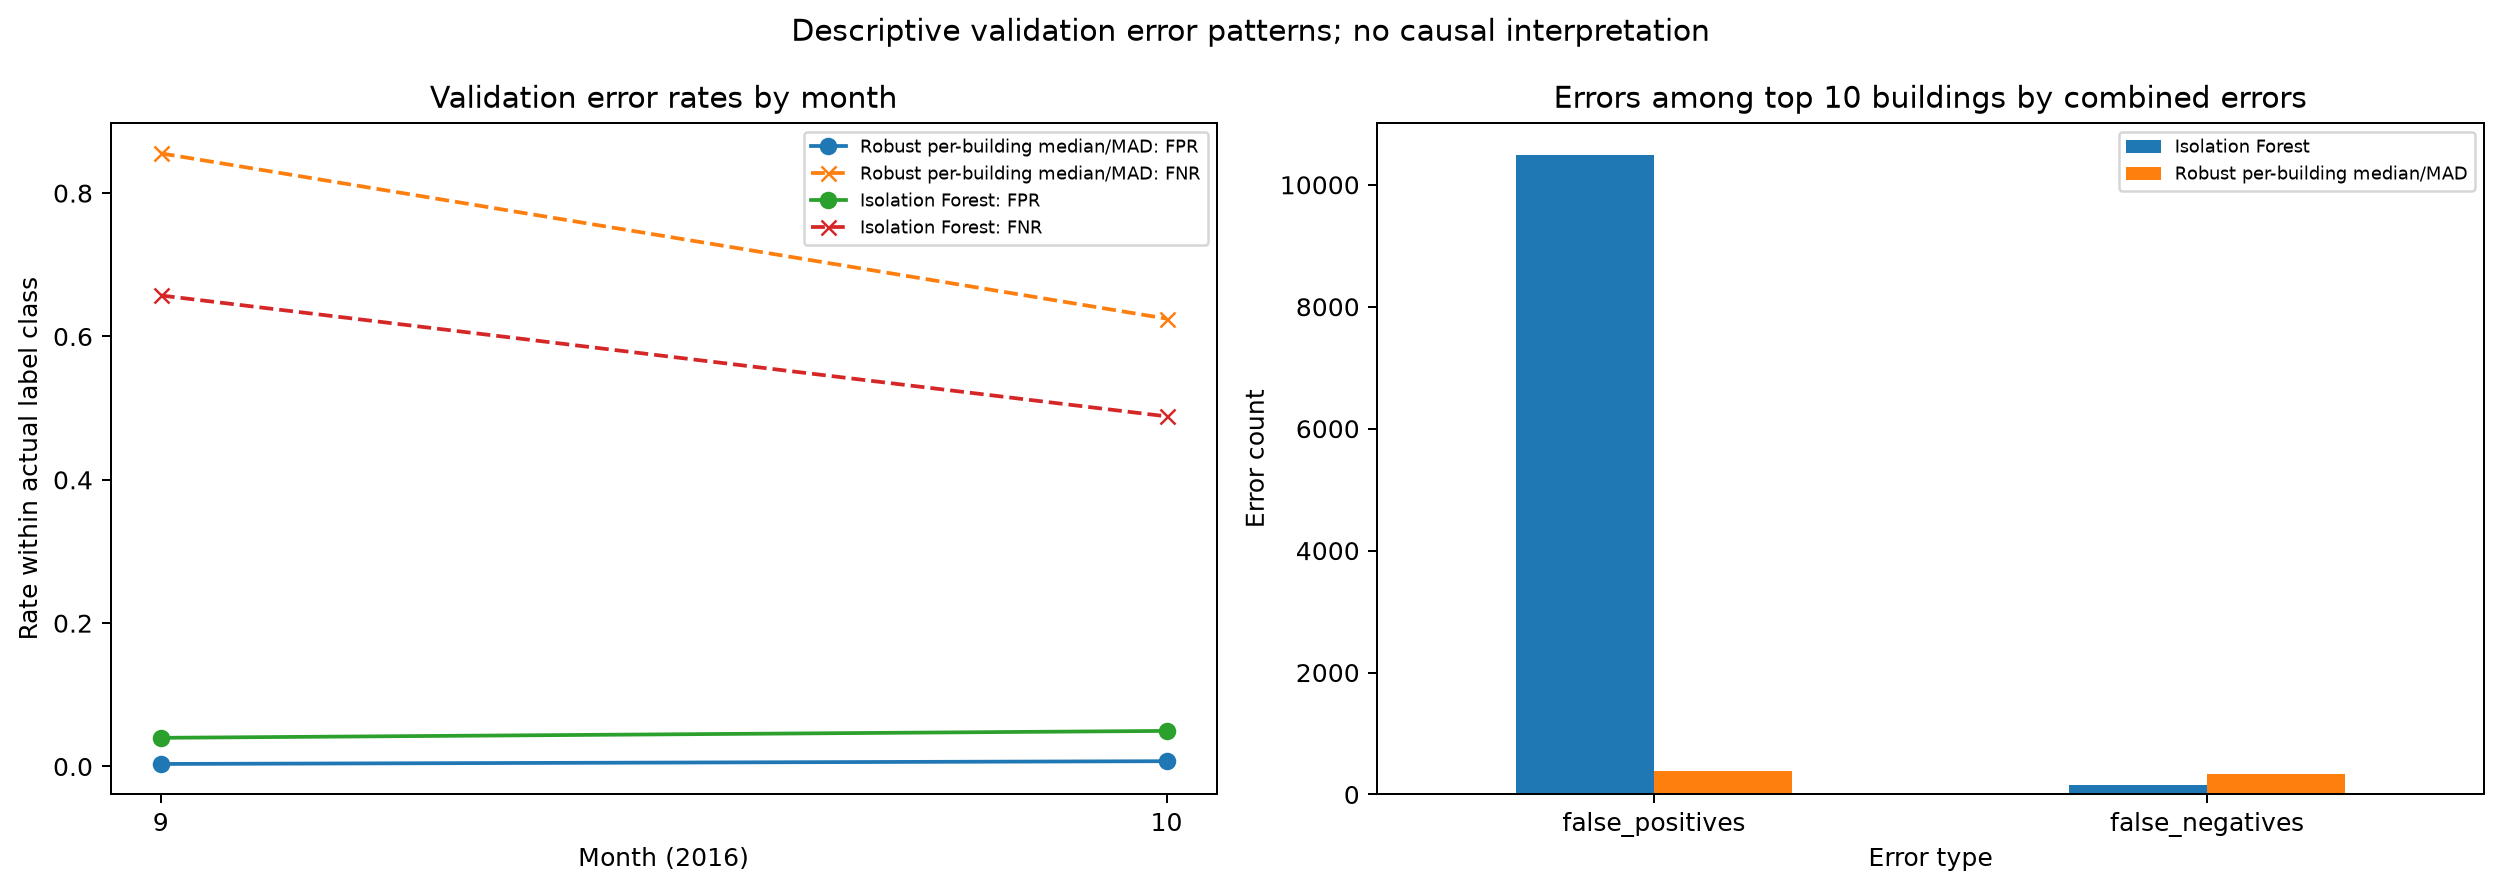

In [18]:
from sklearn.metrics import confusion_matrix

# Align predictions to the existing validation row order and confirm identical evaluation cases.
if not np.array_equal(validation_labels, validation_rows["anomaly"].to_numpy(dtype=int)):
    raise AssertionError("Validation labels are not aligned to the validation rows.")
validation_error_rows = validation_rows[[
    "source_row_index", "building_id", "timestamp_parsed", "meter_reading"
]].copy()
validation_error_rows["label"] = validation_labels
validation_error_rows["month"] = validation_error_rows["timestamp_parsed"].dt.month
validation_error_rows["hour"] = validation_error_rows["timestamp_parsed"].dt.hour
validation_error_rows["log_reading"] = np.log1p(validation_error_rows["meter_reading"])

model_names = list(validation_scores)
for model_name in model_names:
    result = validation_results[model_name]
    if len(result["predictions"]) != len(validation_error_rows):
        raise AssertionError(f"{model_name} predictions have a different row count.")
    expected_predictions = (validation_scores[model_name] >= validation_thresholds[model_name]).astype(int)
    if not np.array_equal(result["predictions"], expected_predictions):
        raise AssertionError(f"{model_name} predictions do not match the selected threshold direction.")
    validation_error_rows[f"prediction::{model_name}"] = result["predictions"]
    validation_error_rows[f"score::{model_name}"] = validation_scores[model_name]
    assert np.array_equal(
        confusion_matrix(validation_labels, result["predictions"], labels=[0, 1]),
        result["confusion_matrix"],
    )

error_summary_rows = []
long_error_parts = []
for model_name in model_names:
    prediction = validation_error_rows[f"prediction::{model_name}"].to_numpy()
    labels = validation_error_rows["label"].to_numpy()
    fp = (labels == 0) & (prediction == 1)
    fn = (labels == 1) & (prediction == 0)
    tn = (labels == 0) & (prediction == 0)
    tp = (labels == 1) & (prediction == 1)
    n_negative, n_positive = int((labels == 0).sum()), int((labels == 1).sum())
    error_summary_rows.append({
        "model": model_name,
        "evaluated_rows": len(labels),
        "false_positives": int(fp.sum()),
        "false_positive_rate_among_label0": float(fp.sum() / n_negative),
        "false_negatives": int(fn.sum()),
        "false_negative_rate_among_label1": float(fn.sum() / n_positive),
        "true_negatives": int(tn.sum()),
        "true_positives": int(tp.sum()),
    })
    part = validation_error_rows[["source_row_index", "building_id", "timestamp_parsed", "month", "hour", "meter_reading", "log_reading", "label"]].copy()
    part["model"] = model_name
    part["score"] = validation_scores[model_name]
    part["prediction"] = prediction
    part["false_positive"] = fp
    part["false_negative"] = fn
    long_error_parts.append(part)

error_summary = pd.DataFrame(error_summary_rows).set_index("model")
print("Validation error counts and rates (label 0 is not guaranteed normal):")
display(error_summary.round(4))

validation_error_long = pd.concat(long_error_parts, ignore_index=True)
monthly = validation_error_long.groupby(["model", "month"]).agg(
    false_positives=("false_positive", "sum"),
    false_negatives=("false_negative", "sum"),
)
monthly_denominators = validation_error_long.drop_duplicates("source_row_index").groupby("month").agg(
    label0_rows=("label", lambda x: int((x == 0).sum())),
    label1_rows=("label", lambda x: int((x == 1).sum())),
)
monthly = monthly.join(monthly_denominators, on="month")
monthly["false_positive_rate"] = monthly["false_positives"] / monthly["label0_rows"]
monthly["false_negative_rate"] = monthly["false_negatives"] / monthly["label1_rows"]
print("Monthly error counts and rates; rates use the month-specific actual-label denominator:")
display(monthly.round(4))

hourly = validation_error_long.groupby(["model", "hour"]).agg(
    false_positives=("false_positive", "sum"), false_negatives=("false_negative", "sum")
)
hourly_denominators = validation_error_long.drop_duplicates("source_row_index").groupby("hour").agg(
    label0_rows=("label", lambda x: int((x == 0).sum())),
    label1_rows=("label", lambda x: int((x == 1).sum())),
)
hourly = hourly.join(hourly_denominators, on="hour")
hourly["false_positive_rate"] = hourly["false_positives"] / hourly["label0_rows"]
hourly["false_negative_rate"] = hourly["false_negatives"] / hourly["label1_rows"]
print("Hourly error summary (descriptive only):")
display(hourly.round(4))

building = validation_error_long.groupby(["model", "building_id"]).agg(
    false_positives=("false_positive", "sum"), false_negatives=("false_negative", "sum")
)
building_denominators = validation_error_long.drop_duplicates("source_row_index").groupby("building_id").agg(
    label0_rows=("label", lambda x: int((x == 0).sum())),
    label1_rows=("label", lambda x: int((x == 1).sum())),
)
building = building.join(building_denominators, on="building_id")
building["false_positive_rate"] = building["false_positives"] / building["label0_rows"].replace(0, np.nan)
building["false_negative_rate"] = building["false_negatives"] / building["label1_rows"].replace(0, np.nan)
building_total_errors = building.groupby("building_id")[["false_positives", "false_negatives"]].sum().sum(axis=1)
top_error_buildings = building_total_errors.sort_values(ascending=False).head(10).index
print("Buildings with the most combined model errors; counts are descriptive, not causal:")
display(building.loc[(slice(None), top_error_buildings), :].sort_values("false_positives", ascending=False).head(20).round(4))

# Reading-range bins use validation predictors only; they are descriptive, not model tuning.
validation_error_long["reading_range"] = pd.qcut(
    validation_error_long["log_reading"], q=5, duplicates="drop"
)
reading_ranges = validation_error_long.groupby(["model", "reading_range"], observed=True).agg(
    rows=("label", "size"), label0_rows=("label", lambda x: int((x == 0).sum())),
    label1_rows=("label", lambda x: int((x == 1).sum())),
    false_positives=("false_positive", "sum"), false_negatives=("false_negative", "sum"),
)
reading_ranges["false_positive_rate"] = reading_ranges["false_positives"] / reading_ranges["label0_rows"].replace(0, np.nan)
reading_ranges["false_negative_rate"] = reading_ranges["false_negatives"] / reading_ranges["label1_rows"].replace(0, np.nan)
print("Error counts/rates by validation log-reading quantile:")
display(reading_ranges.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
monthly_rates = monthly.reset_index()
for model_name in model_names:
    selected = monthly_rates[monthly_rates["model"] == model_name]
    axes[0].plot(selected["month"], selected["false_positive_rate"], marker="o", label=f"{model_name}: FPR")
    axes[0].plot(selected["month"], selected["false_negative_rate"], marker="x", linestyle="--", label=f"{model_name}: FNR")
axes[0].set(title="Validation error rates by month", xlabel="Month (2016)", ylabel="Rate within actual label class")
axes[0].set_xticks(sorted(validation_error_rows["month"].unique()))
axes[0].legend(fontsize=7)

building_plot = building.loc[(slice(None), top_error_buildings), :].reset_index()
building_totals = building_plot.groupby("model").agg(
    false_positives=("false_positives", "sum"), false_negatives=("false_negatives", "sum")
).T
building_totals.plot(kind="bar", ax=axes[1])
axes[1].set(title="Errors among top 10 buildings by combined errors", ylabel="Error count", xlabel="Error type")
axes[1].tick_params(axis="x", labelrotation=0)
axes[1].legend(fontsize=7)
fig.suptitle("Descriptive validation error patterns; no causal interpretation")
fig.tight_layout()
from pathlib import Path
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)
fig.savefig(figures_dir / "validation_error_patterns.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Validation label prevalence: {validation_labels.mean():.3%}; an always-label-0 rule would be "
      f"{1 - validation_labels.mean():.3%} accurate while detecting no annotated outages.")

### Report-ready interpretation guide

Use the executed validation tables and figures above for claims. The validation PR curve and average-precision score show ranking quality in a setting with rare outage annotations; the thresholded confusion matrices show the distinct false-alarm/missed-outage trade-off. Accuracy is intentionally not the main metric: an all-zero prediction would be highly accurate solely because label 1 is rare. Compare monthly, hourly, building, and reading-range error rates descriptively, remembering that label 0 means “not marked as outage.” These temporal partitions evaluate later periods for buildings also represented in development; they do not establish performance on unseen buildings. All reported model metrics exclude missing meter readings. The previously performed final-holdout evaluation is recorded in the preceding section and is not revisited by this analysis; it must not be used to revise features, model settings, or thresholds.